# Compare WERM against McScan for dense (and slightly correlated) signals

In [ ]:
from WERM.config import unif_prior_to_η_ϕ, unif_prior_to_η_ϕ_combinations
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import WERM.gof
import WERM.performance_measures
import WERM.comparison
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(10)

p = 250
L = 3 # num signals. L-1 changepoints

δ_list = [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
noise_std = 0.5
num_trials = 10

fractional_chgpt_locations = np.array([0.3, 0.7])
# fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
ERM_size_arr = np.zeros((len(δ_list), num_trials))
ERM_runtime = np.zeros((len(δ_list), num_trials))
DCDP_haus_arr = np.zeros((len(δ_list), num_trials))
DCDP_size_arr = np.zeros((len(δ_list), num_trials))
McScan_haus_arr = np.zeros((len(δ_list), num_trials))
McScan_size_arr = np.zeros((len(δ_list), num_trials))
McScan_runtime = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    # Changepoint locations
    Δ = lambda n: int(n/10)

    # For estimating size
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    # For estimating location
    # Lmin = L
    # Lmax = L
    # p_l = None
    # num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    ϕ_normalized = ϕ / ϕ.sum(axis = 1)[:, None]
    plt.plot(ϕ_normalized.T)
    plt.show()
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    # Subsampling
    # subsample_factor = 1
    # n_subsampled = int(n/subsample_factor)
    # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # η_arr_subsampled = η_arr_subsampled * subsample_factor # Rescale η_arr_subsampled to match η_arr

    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            Σ[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    γ_squared_over_δ = 8
    # Design a non-trivial LxL covariance
    covvy = np.zeros((L, L))
    for i_ in range(L):
        for j_ in range(L):
            covvy[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    # covvy = np.block([[1, 0.4], [0.4, 1]])
    B̃_cov = γ_squared_over_δ * δ * covvy # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T

        Θ = X @ B̃
        y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

        # --- Run Weighted ERM --- #
        B̂_erm = np.zeros((p, L))
        β̂_erm_list = [None for ℓ_ in range(L)]

        # Time the execution of the ERM and save it
        start_time_ERM = time.time()
        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]

            print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            print("Done regressing on signal.")
            β̂_erm = sk_lin_reg.coef_
            β̂_erm_list[ℓ_] = β̂_erm

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.lin_reg_opt_chgpt_gof(X @ B̂_erm, y, η_arr, p_η_arr, σ = noise_std, ϵ = 0.005)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        ERM_runtime[i, trial_num] = time.time() - start_time_ERM

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        ERM_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        ### --- Run DCDP, and record the runtime --- ###
        # print("Running DCDP...")
        # DCDP_res = np.array(WERM.comparison.DCDP(X, np.array(y), λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # print("DCDP_res: ", DCDP_res)
        # # plot a vertical line at the DCDP estimated change point location
        # [plt.axvline(x=loc, color = 'b', linestyle='-.', alpha = 0.8, label="DCDP chgpt") for loc in DCDP_res]
        # DCDP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(DCDP_res, true_chgpt_locations(n)))
        # DCDP_size_arr[i, trial_num] = (len(DCDP_res[DCDP_res != -1]))

        ### --- Run McScan --- ###
        start_time_McScan = time.time()
        print("Running McScan...")
        try: 
            McScan_res = np.array(WERM.comparison.run_mcscan(X, np.array(y).reshape(-1, 1)))
        except:
            McScan_res = np.array([-1])
        print("McScan_res: ", McScan_res)
        McScan_runtime[i, trial_num] = time.time() - start_time_McScan
        # plot a vertical line at the McScan estimated change point location
        [plt.axvline(x=loc, color='c', linestyle='-.', alpha = 0.8, label="McScan chgpt") for loc in McScan_res]
        McScan_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(McScan_res, true_chgpt_locations(n)))
        McScan_size_arr[i, trial_num] = (len(McScan_res[McScan_res != -1]))

        plt.legend()
        plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_haus_arr, axis = 1), yerr = np.std(DCDP_haus_arr, axis = 1), label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = np.std(McScan_haus_arr, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_size_arr, axis = 1), yerr = np.std(DCDP_haus_arr, axis = 1), label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = np.std(McScan_haus_arr, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = np.std(McScan_runtime, axis = 1), label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.xlabel("δ")
plt.ylabel("Runtime")
plt.legend()
plt.show()

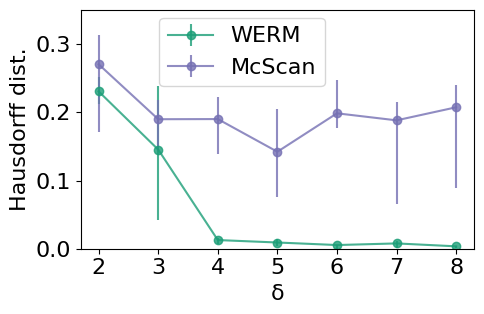

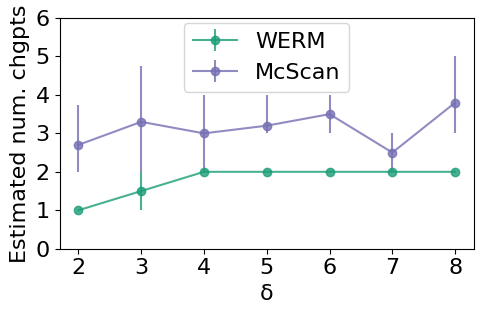

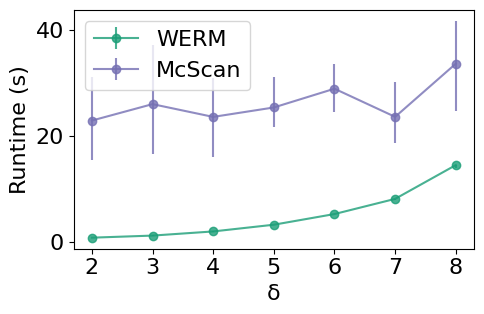

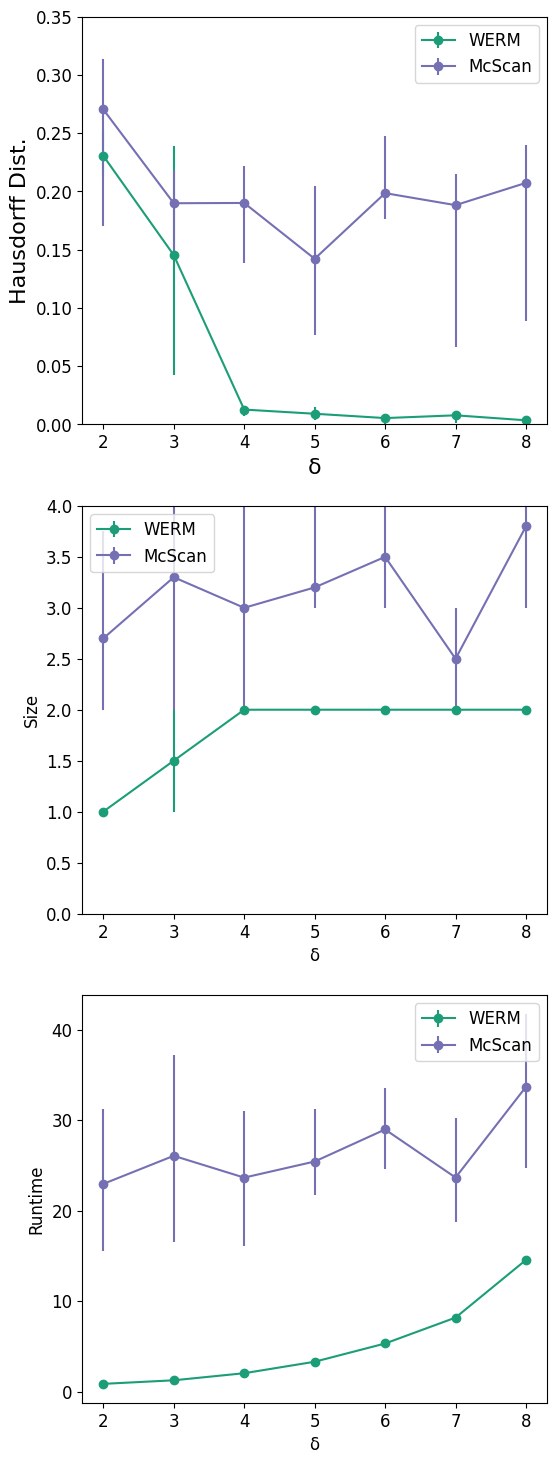

In [52]:
# Save the results
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/erm_corr_arr.npy", erm_corr_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/erm_MSE_arr.npy", erm_MSE_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_haus_arr.npy", ERM_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_size_arr.npy", ERM_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/ERM_runtime.npy", ERM_runtime)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_haus_arr.npy", DCDP_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/DCDP_size_arr.npy", DCDP_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_haus_arr.npy", McScan_haus_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_size_arr.npy", McScan_size_arr)
np.save("results/linear_model_comparison/McScan_dense_signal_comparison/McScan_runtime.npy", McScan_runtime)

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, 0.35))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Hausdorff dist.", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.2, 0.68))
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_haus" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 3))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 16}, loc = (0.3, 0.68))
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_size" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.xlabel("δ", fontsize=16)
plt.ylabel("Runtime (s)", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks([0, 20, 40], fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison_runtime" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Plot the above three figures on top of each other as subplots
fig, axs = plt.subplots(3, 1, figsize=(6, 18))

# Hausdorff estimation plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
axs[0].errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[0].errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[0].set_ylim((0, 0.35))
axs[0].set_xlabel("δ", fontsize=16)
axs[0].set_ylabel("Hausdorff Dist.", fontsize=16)
axs[0].legend()

# Hausdorff size plots
axs[1].errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[1].errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[1].set_ylim((0, L + 1))
axs[1].set_xlabel("δ")
axs[1].set_ylabel("Size")
axs[1].legend()

# Runtime plots
axs[2].errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[2].errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[2].set_xlabel("δ")
axs[2].set_ylabel("Runtime")
axs[2].legend()
plt.savefig("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison.pdf")

# Save the figure as a tikz file, and use a workaround to make the legend work
import tikzplotlib
def tikzplotlib_fix_ncols(obj):
    """
    workaround for matplotlib 3.6 renamed legend's _ncol to _ncols, which breaks tikzplotlib
    """
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    for child in obj.get_children():
        tikzplotlib_fix_ncols(child)
tikzplotlib_fix_ncols(fig)
tikzplotlib.save("figures/linear_model_comparison/McScan_dense_signal_comparison/linear_model_comparison.tex")


plt.show()



# Compare WERM against McScan and DCDP for individually sparse signals

  0%|          | 0/7 [00:00<?, ?it/s]

δ =  0.5


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

  0%|          | 0/2278 [00:00<?, ?it/s]

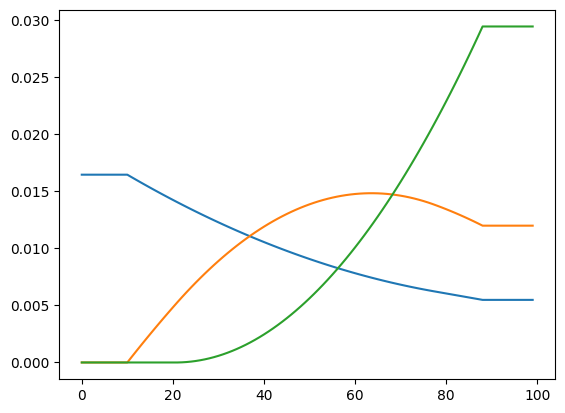

ρ:  [[ 0.5681429   0.00412321 -0.00817488]
 [ 0.00412321  0.45599231  0.02610897]
 [-0.00817488  0.02610897  0.59639057]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 39 63

McScan_res:  [39 63]


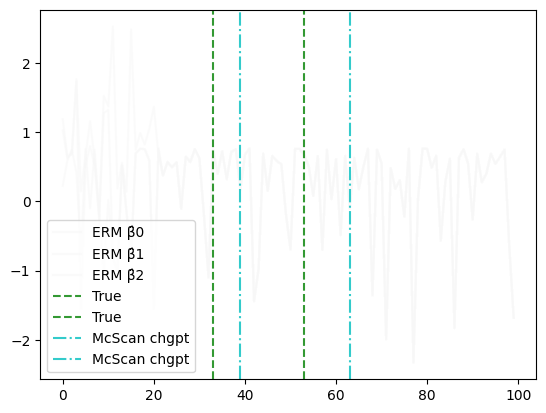

  7%|▋         | 1/15 [00:12<02:50, 12.17s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 46 79

McScan_res:  [46 79]


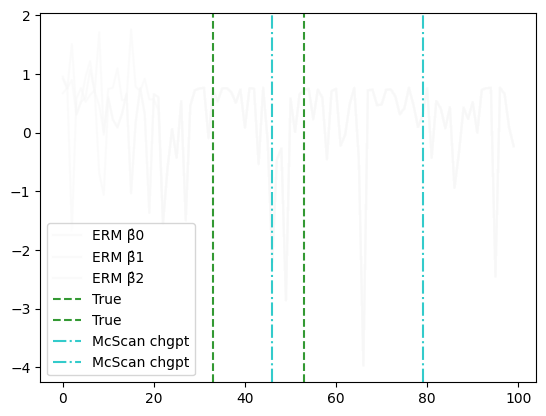

 13%|█▎        | 2/15 [00:22<02:22, 10.99s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 23 70

McScan_res:  [23 70]


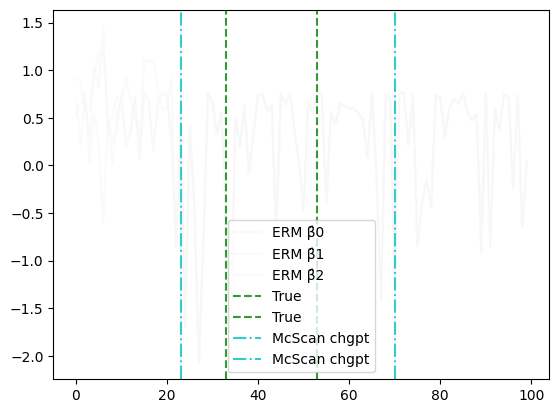

 20%|██        | 3/15 [00:32<02:05, 10.47s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 43 78

McScan_res:  [43 78]


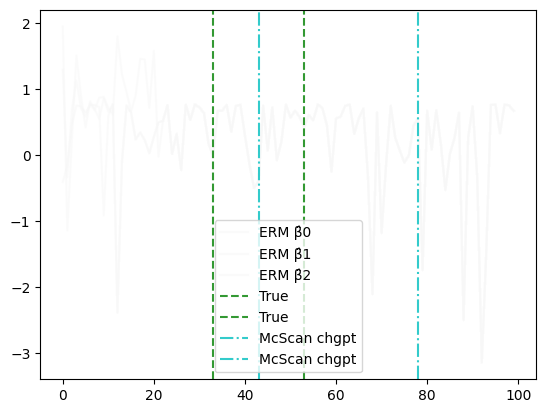

 27%|██▋       | 4/15 [00:42<01:52, 10.22s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 78

McScan_res:  [78]


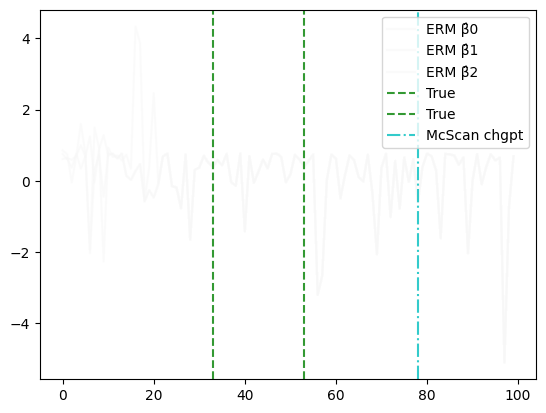

 33%|███▎      | 5/15 [00:47<01:25,  8.53s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 24 74

McScan_res:  [24 74]


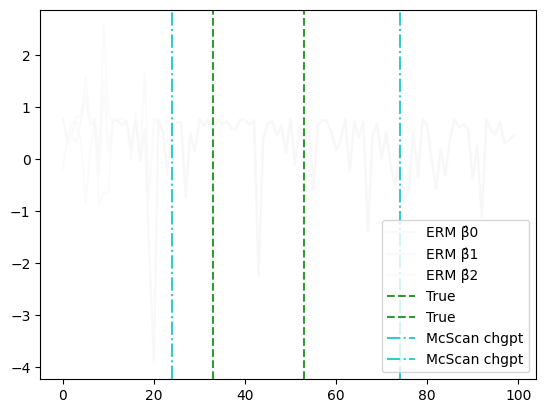

 40%|████      | 6/15 [00:57<01:22,  9.15s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 24 69

McScan_res:  [24 69]


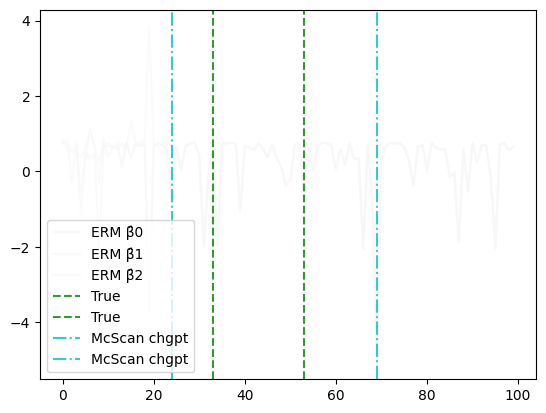

 47%|████▋     | 7/15 [01:07<01:14,  9.36s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 52

McScan_res:  [52]


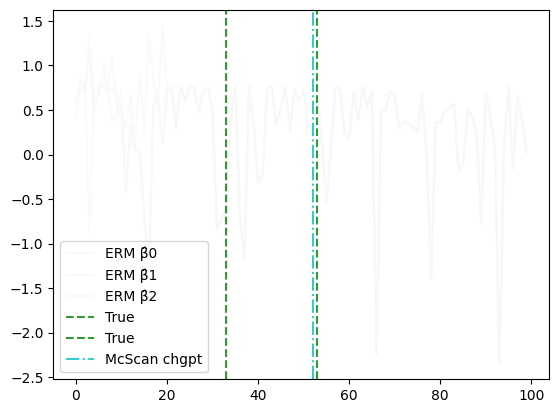

 53%|█████▎    | 8/15 [01:13<00:56,  8.10s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 66

McScan_res:  [66]


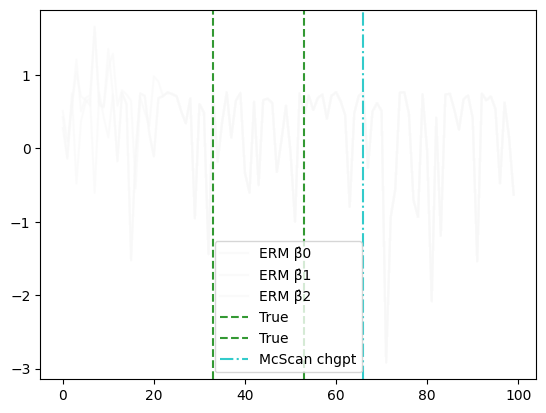

 60%|██████    | 9/15 [01:18<00:43,  7.27s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 59

McScan_res:  [59]


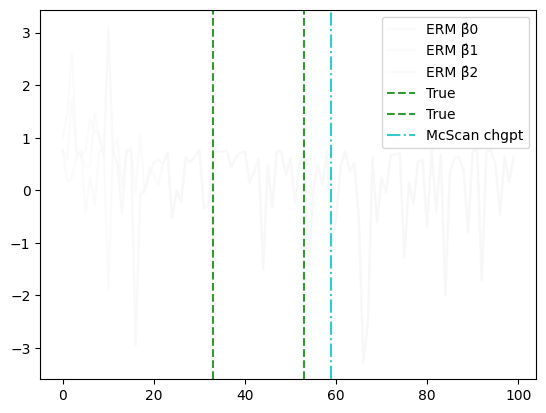

 67%|██████▋   | 10/15 [01:23<00:33,  6.70s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 27

McScan_res:  [27]


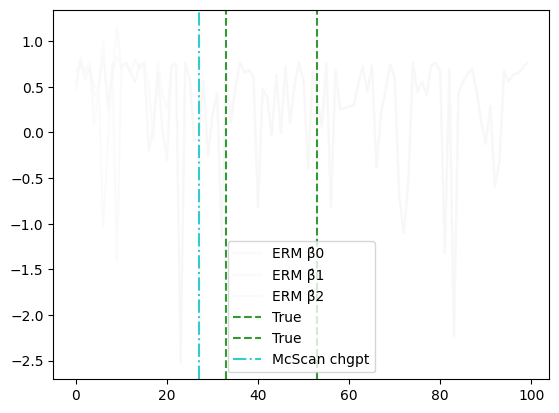

 73%|███████▎  | 11/15 [01:29<00:25,  6.33s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 52 70

McScan_res:  [52 70]


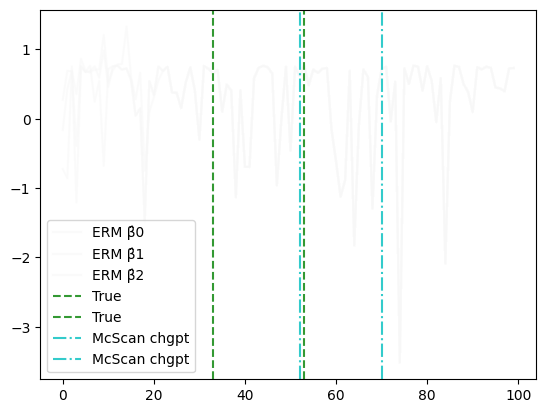

 80%|████████  | 12/15 [01:39<00:22,  7.53s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 29

McScan_res:  [29]


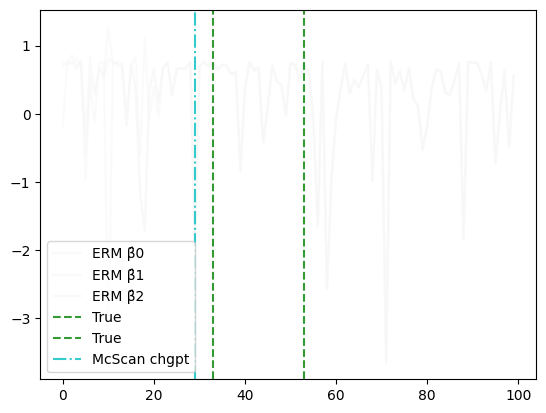

 87%|████████▋ | 13/15 [01:45<00:13,  6.86s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 29

McScan_res:  [29]


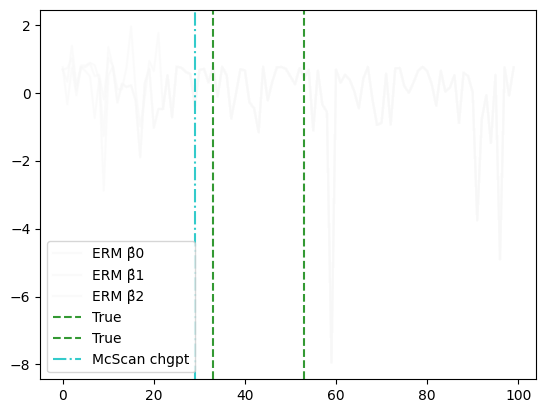

 93%|█████████▎| 14/15 [01:50<00:06,  6.45s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 31 73

McScan_res:  [31 73]


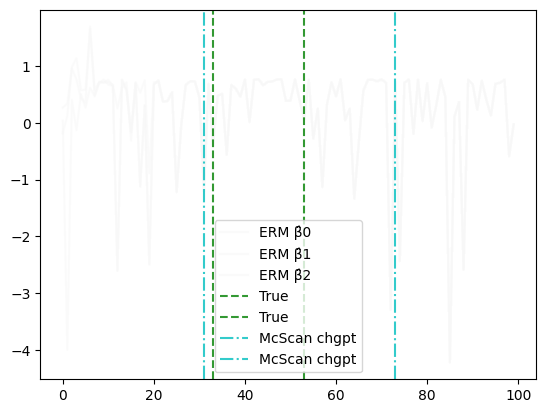

 14%|█▍        | 1/7 [02:00<12:05, 120.96s/it]

δ =  1.0


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/158 [00:00<?, ?it/s]

  0%|          | 0/9453 [00:00<?, ?it/s]

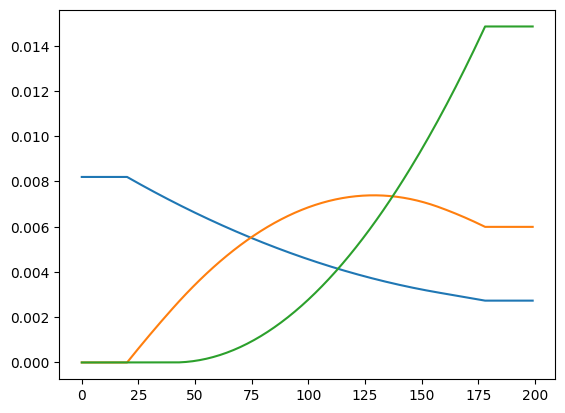

ρ:  [[ 4.83273373e-01  1.02639662e-02 -1.17448771e-04]
 [ 1.02639662e-02  6.05506196e-01 -3.85043363e-02]
 [-1.17448771e-04 -3.85043363e-02  4.89843538e-01]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 68

McScan_res:  [68]


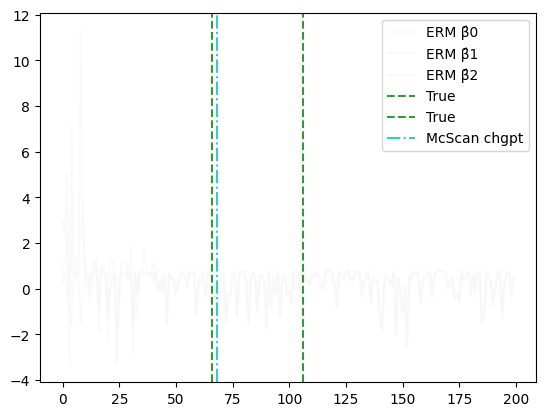

  7%|▋         | 1/15 [00:06<01:29,  6.41s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  96 167

McScan_res:  [ 96 167]


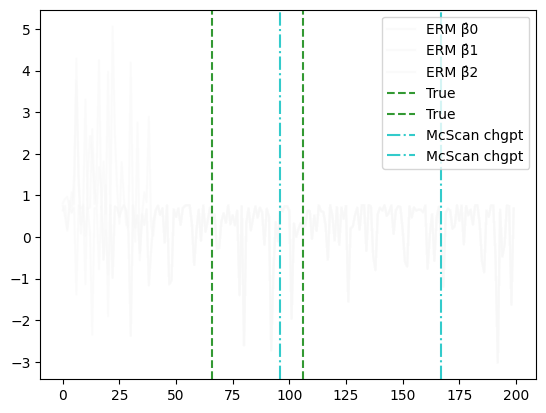

 13%|█▎        | 2/15 [00:16<01:50,  8.53s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  24  61 112 175

McScan_res:  [ 24  61 112 175]


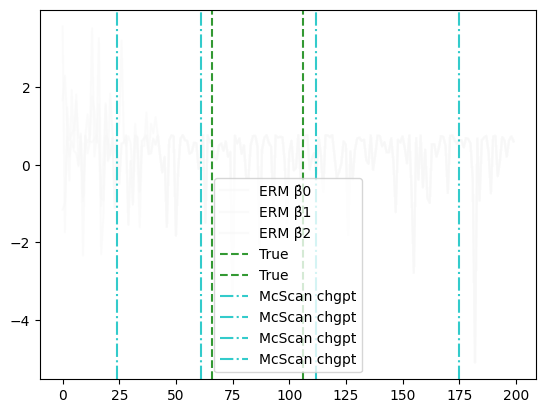

 20%|██        | 3/15 [00:35<02:40, 13.40s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 124

McScan_res:  [124]


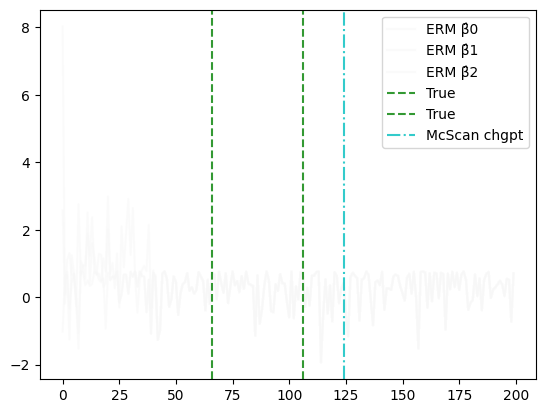

 27%|██▋       | 4/15 [00:41<01:53, 10.31s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  72 102

McScan_res:  [ 72 102]


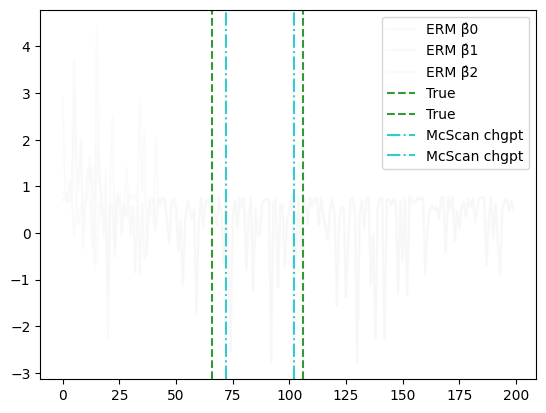

 33%|███▎      | 5/15 [00:51<01:42, 10.24s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 130 158

McScan_res:  [130 158]


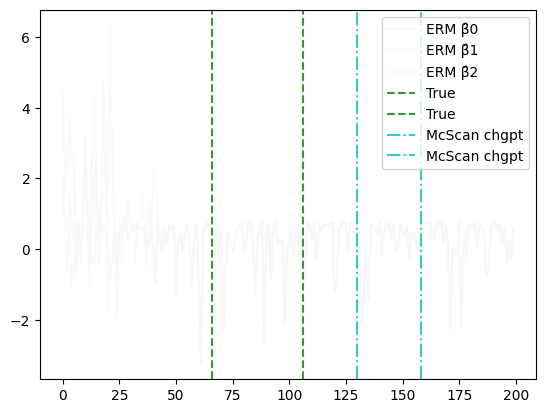

 40%|████      | 6/15 [01:01<01:31, 10.14s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  68 152

McScan_res:  [ 68 152]


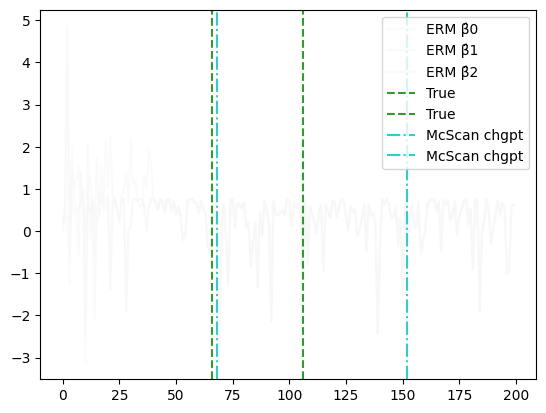

 47%|████▋     | 7/15 [01:11<01:21, 10.20s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  82 102 174

McScan_res:  [ 82 102 174]


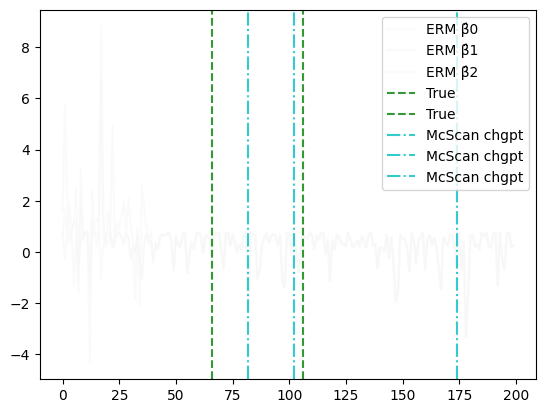

 53%|█████▎    | 8/15 [01:26<01:21, 11.66s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 102 135

McScan_res:  [102 135]


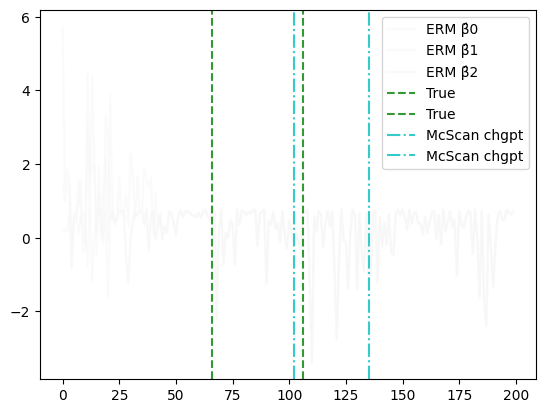

 60%|██████    | 9/15 [01:36<01:06, 11.06s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  31  55 106 178

McScan_res:  [ 31  55 106 178]


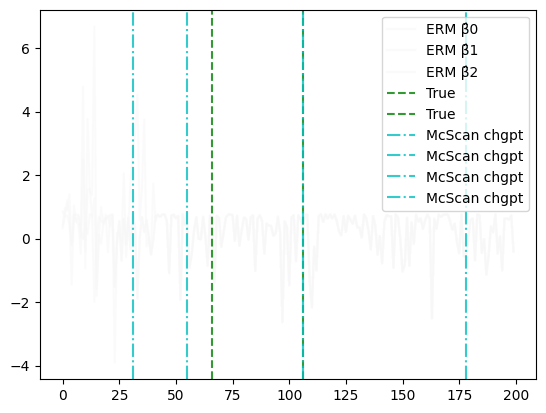

 67%|██████▋   | 10/15 [01:55<01:07, 13.50s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 115

McScan_res:  [115]


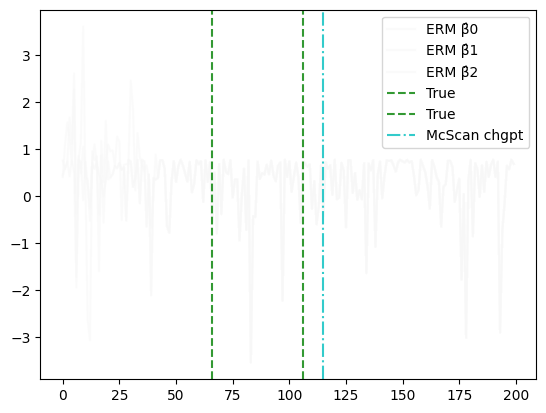

 73%|███████▎  | 11/15 [02:00<00:44, 11.16s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  86 108

McScan_res:  [ 86 108]


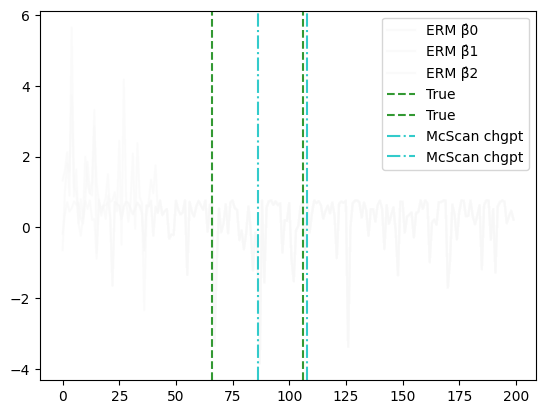

 80%|████████  | 12/15 [02:10<00:32, 10.77s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 97

McScan_res:  [97]


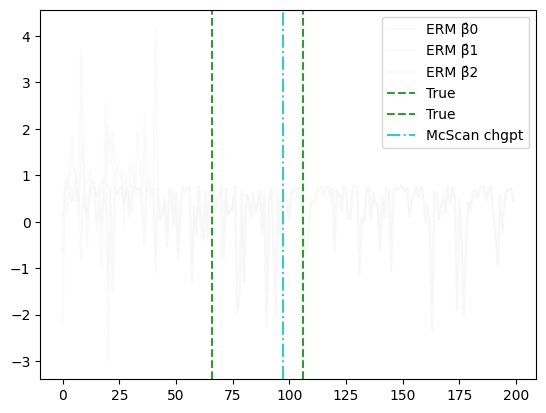

 87%|████████▋ | 13/15 [02:16<00:18,  9.12s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  91 141

McScan_res:  [ 91 141]


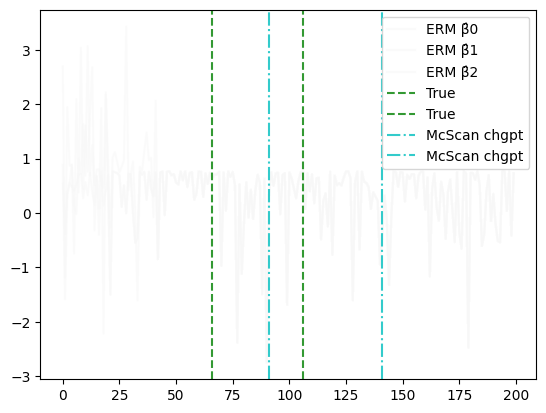

 93%|█████████▎| 14/15 [02:26<00:09,  9.35s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  []
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  67 178

McScan_res:  [ 67 178]


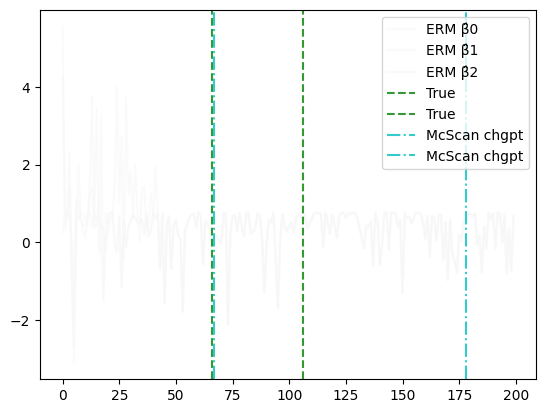

 29%|██▊       | 2/7 [04:37<11:49, 141.96s/it]

δ =  1.5


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/238 [00:00<?, ?it/s]

  0%|          | 0/21528 [00:00<?, ?it/s]

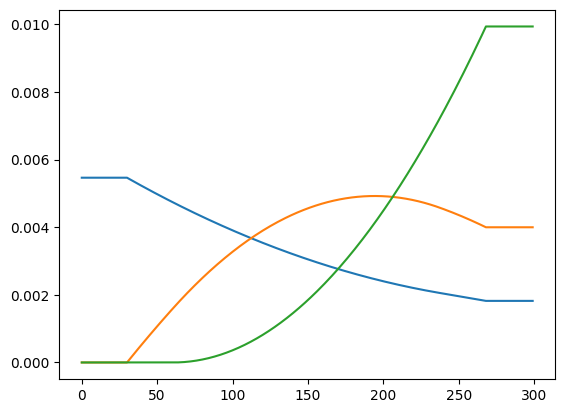

ρ:  [[ 0.54622585 -0.02190799  0.01277421]
 [-0.02190799  0.52676773 -0.03003973]
 [ 0.01277421 -0.03003973  0.61078061]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [117]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 60

McScan_res:  [60]


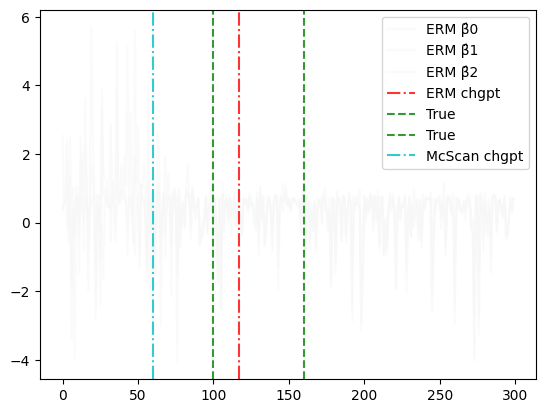

  7%|▋         | 1/15 [00:06<01:27,  6.23s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [ 95 133]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 193 237

McScan_res:  [193 237]


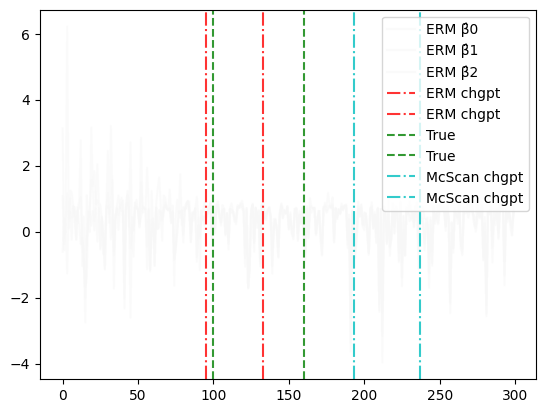

 13%|█▎        | 2/15 [00:16<01:51,  8.54s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [119]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  53 165

McScan_res:  [ 53 165]


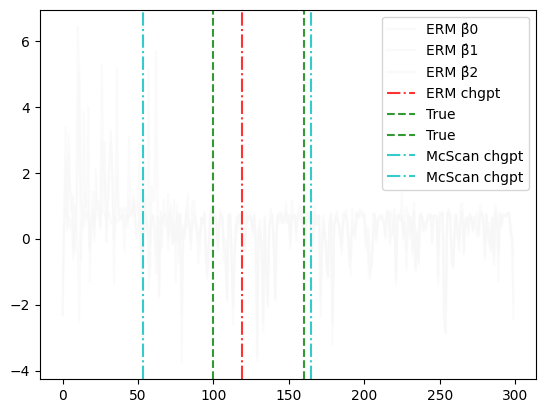

 20%|██        | 3/15 [00:26<01:51,  9.32s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [ 87 120]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 100 181

McScan_res:  [100 181]


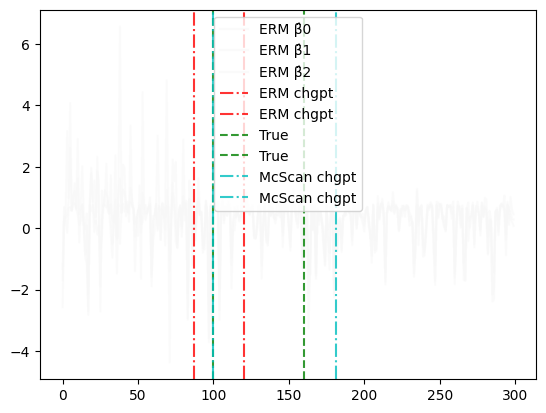

 27%|██▋       | 4/15 [00:36<01:46,  9.70s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [110]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 221

McScan_res:  [221]


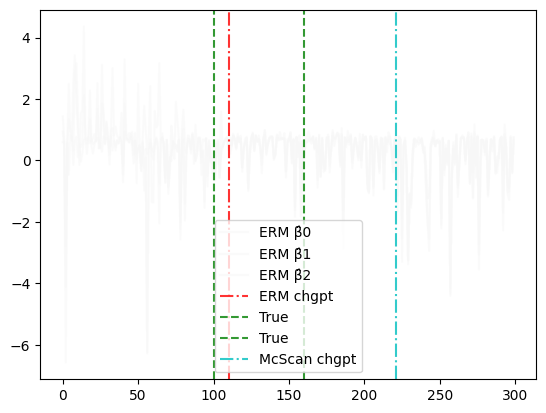

 33%|███▎      | 5/15 [00:42<01:22,  8.22s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [111]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 106 149

McScan_res:  [106 149]


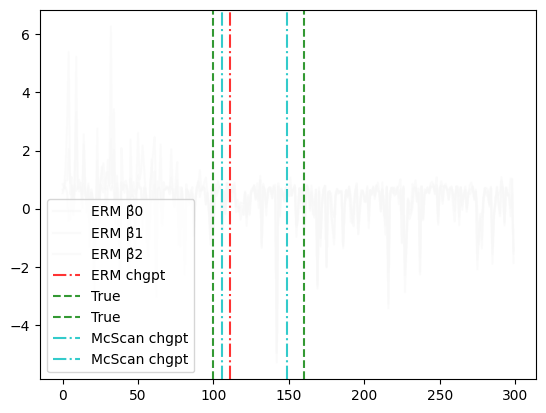

 40%|████      | 6/15 [00:52<01:20,  8.92s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [ 94 125]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 179 246

McScan_res:  [179 246]


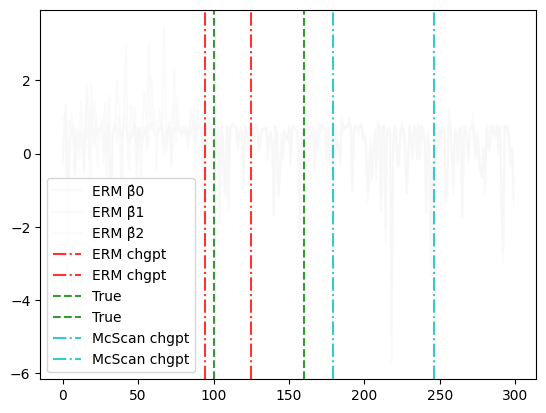

 47%|████▋     | 7/15 [01:02<01:14,  9.28s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [102]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 101 194 205

McScan_res:  [101 194 205]


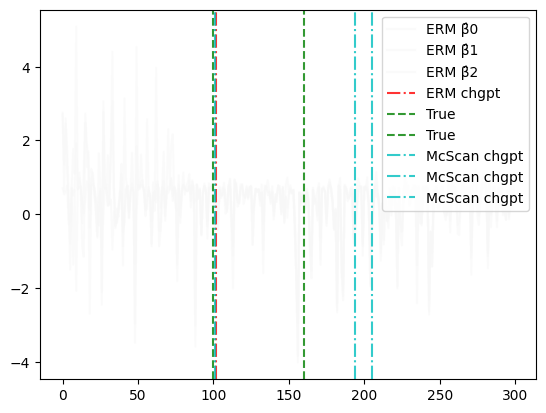

 53%|█████▎    | 8/15 [01:16<01:14, 10.66s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [119]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  99 225

McScan_res:  [ 99 225]


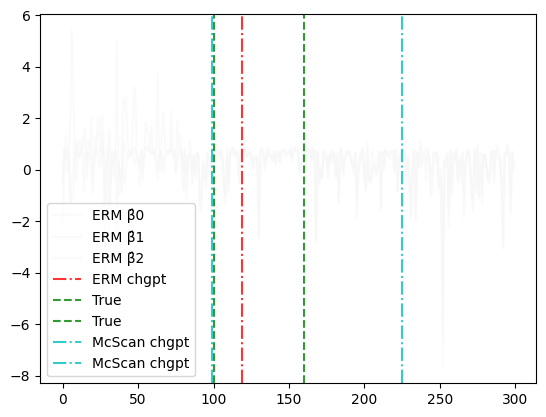

 60%|██████    | 9/15 [01:26<01:02, 10.41s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [119]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 113 164

McScan_res:  [113 164]


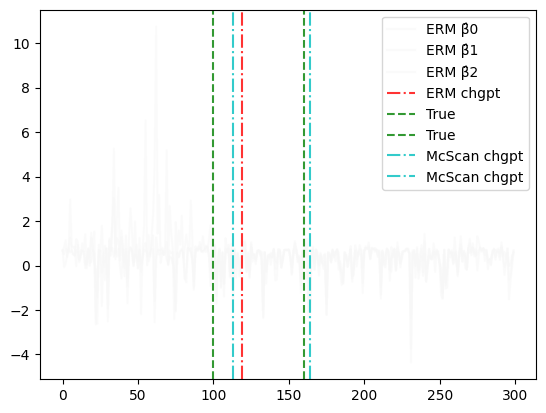

 67%|██████▋   | 10/15 [01:36<00:51, 10.26s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [102 145]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 118 154

McScan_res:  [118 154]


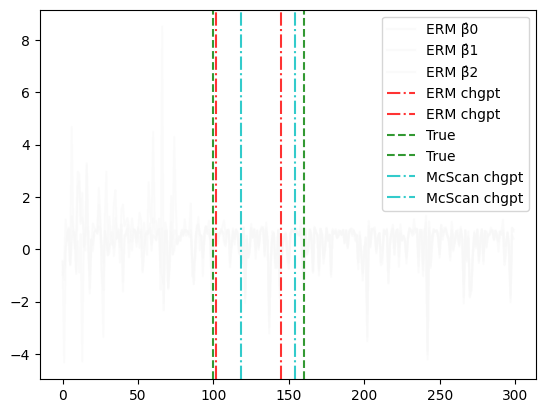

 73%|███████▎  | 11/15 [01:46<00:40, 10.15s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [119]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  52 168

McScan_res:  [ 52 168]


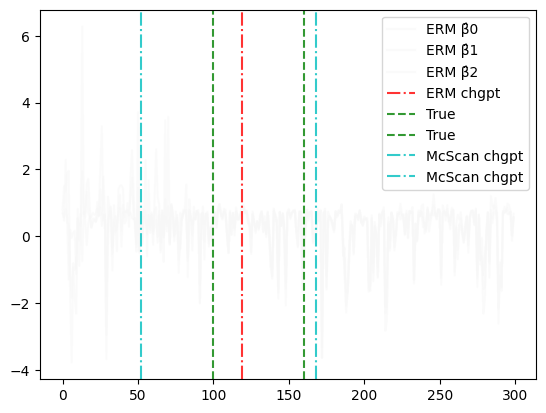

 80%|████████  | 12/15 [01:56<00:30, 10.17s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [110]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  37 175

McScan_res:  [ 37 175]


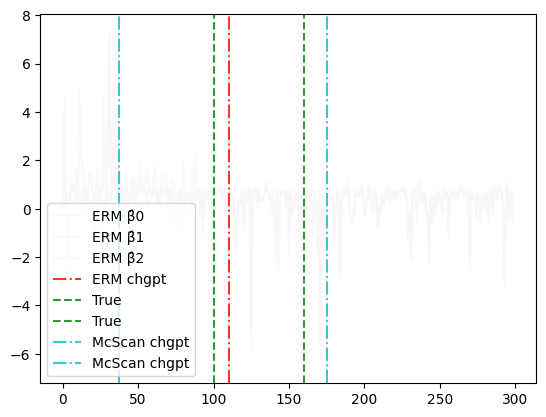

 87%|████████▋ | 13/15 [02:06<00:20, 10.05s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [113]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  77  91 164

McScan_res:  [ 77  91 164]


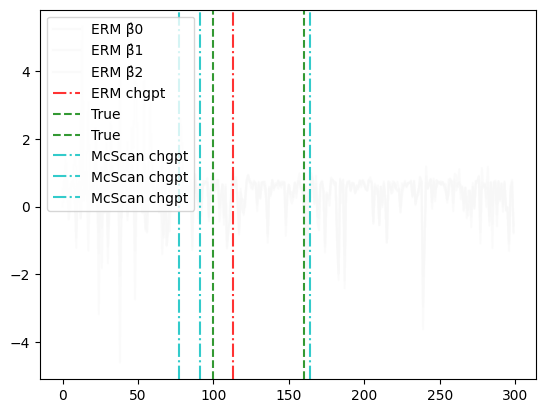

 93%|█████████▎| 14/15 [02:20<00:11, 11.24s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [113]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  99 173 188

McScan_res:  [ 99 173 188]


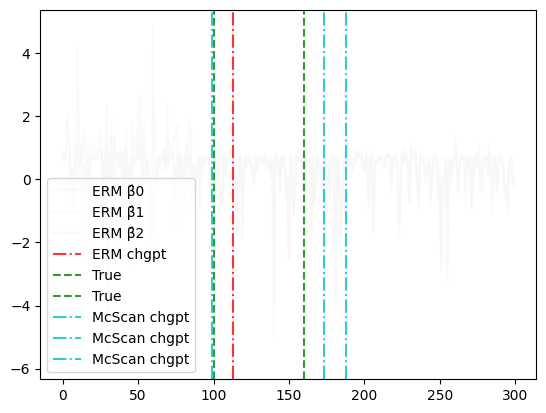

 43%|████▎     | 3/7 [07:12<09:51, 147.92s/it]

δ =  2.0


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/318 [00:00<?, ?it/s]

  0%|          | 0/38503 [00:00<?, ?it/s]

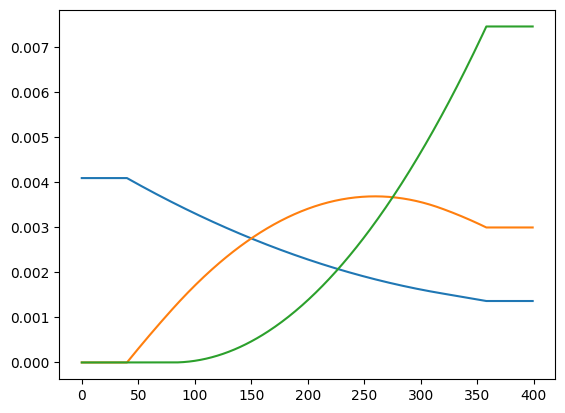

ρ:  [[ 0.51841839 -0.00170196  0.0157766 ]
 [-0.00170196  0.48777201 -0.00727366]
 [ 0.0157766  -0.00727366  0.45266444]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [123 220]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 152 212 376

McScan_res:  [152 212 376]


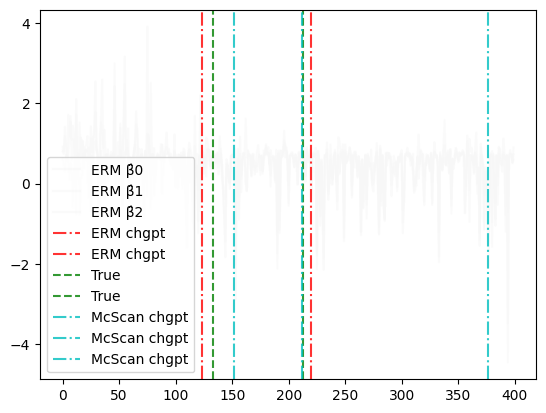

  7%|▋         | 1/15 [00:15<03:36, 15.48s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [123 192]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 172 252

McScan_res:  [172 252]


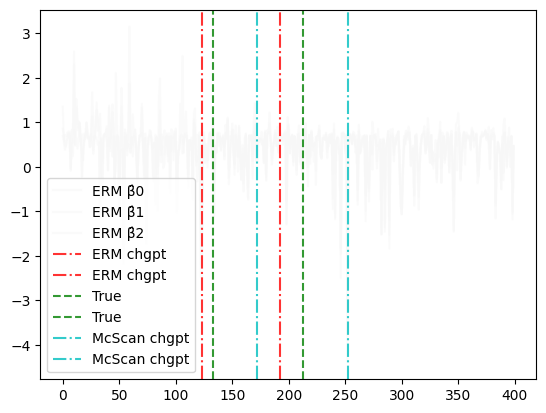

 13%|█▎        | 2/15 [00:25<02:37, 12.08s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [130 201]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  33  53 152 212 259

McScan_res:  [ 33  53 152 212 259]


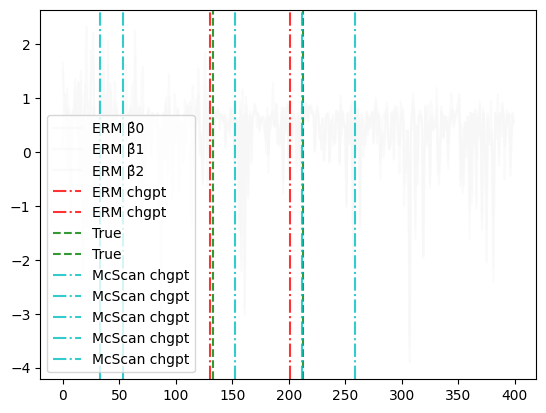

 20%|██        | 3/15 [00:49<03:31, 17.66s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [155 212]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 134 220 302

McScan_res:  [134 220 302]


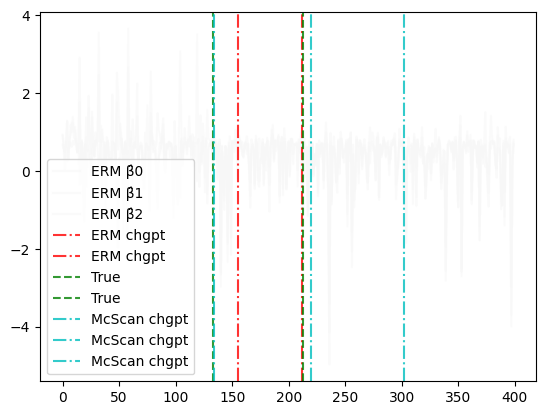

 27%|██▋       | 4/15 [01:04<03:01, 16.54s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [178 219]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 215 243

McScan_res:  [215 243]


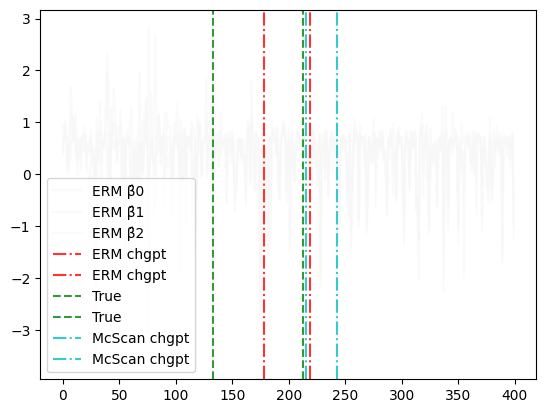

 33%|███▎      | 5/15 [01:13<02:20, 14.07s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [164 210]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 124 218 358

McScan_res:  [124 218 358]


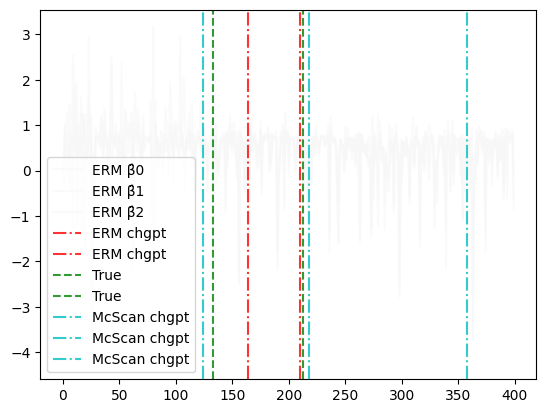

 40%|████      | 6/15 [01:28<02:08, 14.31s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [138 216]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  53 160

McScan_res:  [ 53 160]


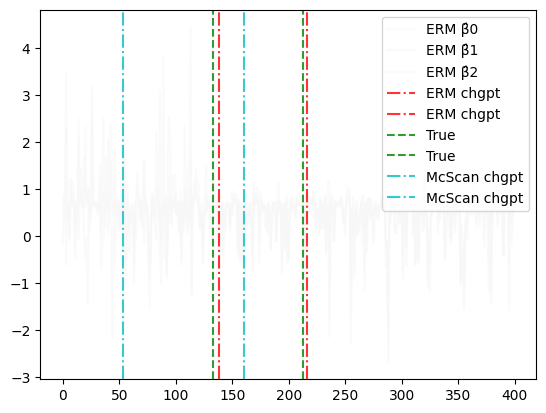

 47%|████▋     | 7/15 [01:39<01:44, 13.01s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [148 194]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 138 303 338

McScan_res:  [138 303 338]


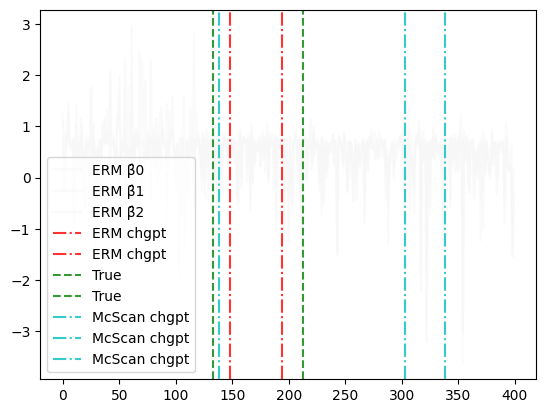

 53%|█████▎    | 8/15 [01:53<01:34, 13.52s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [150 209]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  63 154 214 303 330

McScan_res:  [ 63 154 214 303 330]


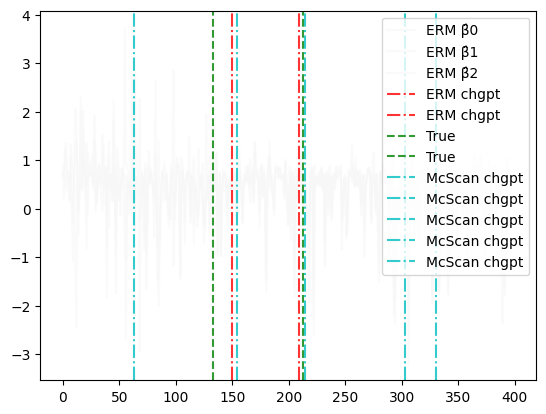

 60%|██████    | 9/15 [02:16<01:38, 16.48s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [159 224]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  66 313

McScan_res:  [ 66 313]


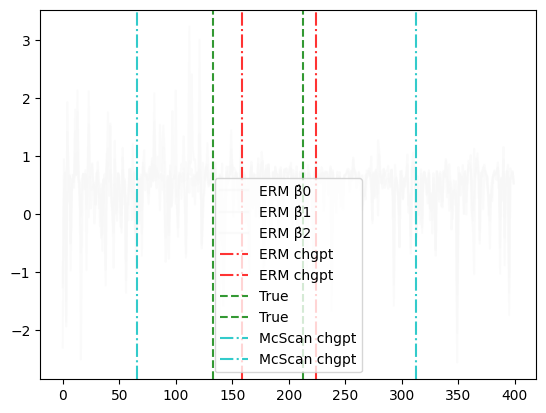

 67%|██████▋   | 10/15 [02:26<01:11, 14.38s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [122 215]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  75 131 195

McScan_res:  [ 75 131 195]


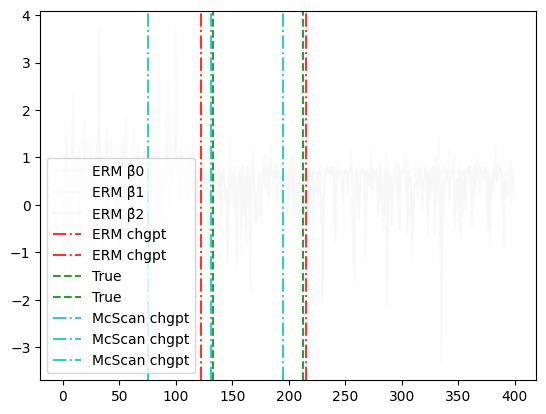

 73%|███████▎  | 11/15 [02:40<00:57, 14.44s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [132 208]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 131 140 215 281

McScan_res:  [131 140 215 281]


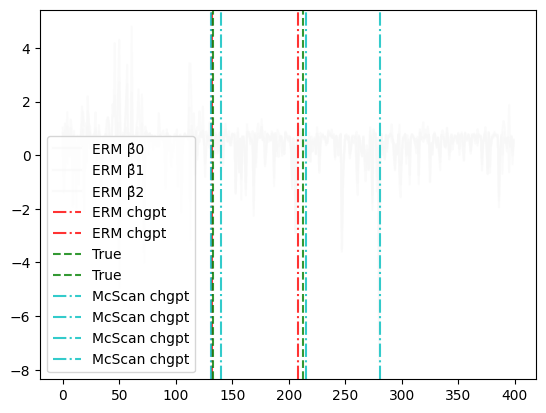

 80%|████████  | 12/15 [02:58<00:45, 15.24s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [159 207]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 126 200

McScan_res:  [126 200]


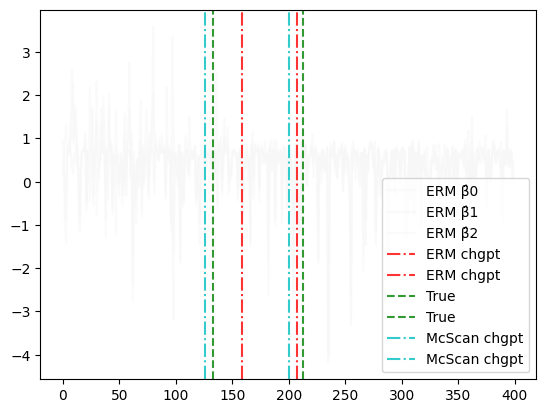

 87%|████████▋ | 13/15 [03:08<00:27, 13.68s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [152 210]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 128 185 227

McScan_res:  [128 185 227]


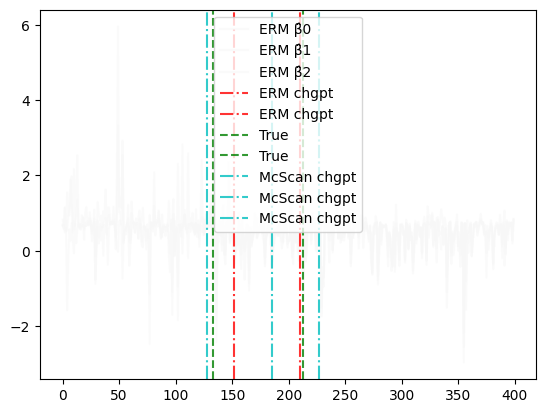

 93%|█████████▎| 14/15 [03:22<00:13, 13.86s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [126 209]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  69 284

McScan_res:  [ 69 284]


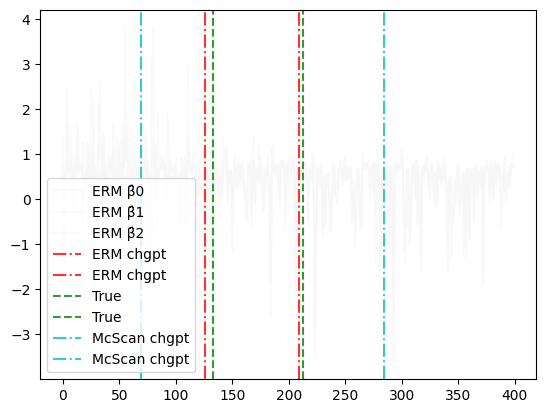

 57%|█████▋    | 4/7 [10:45<08:40, 173.55s/it]

δ =  2.5


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/60378 [00:00<?, ?it/s]

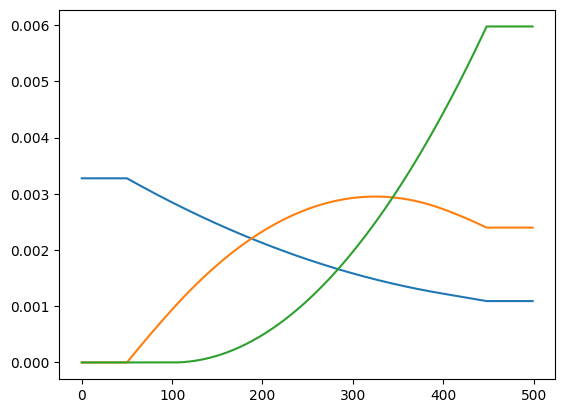

ρ:  [[ 0.53309678 -0.01671998  0.05463607]
 [-0.01671998  0.5350561   0.00826545]
 [ 0.05463607  0.00826545  0.48253842]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [187 266]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 113 163 281

McScan_res:  [113 163 281]


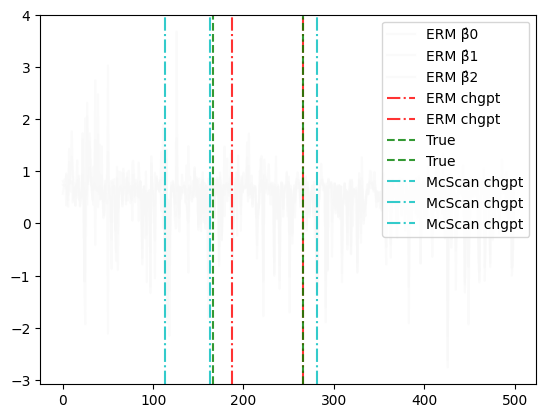

  7%|▋         | 1/15 [00:15<03:40, 15.75s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [198 263]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 188 210 351 377

McScan_res:  [188 210 351 377]


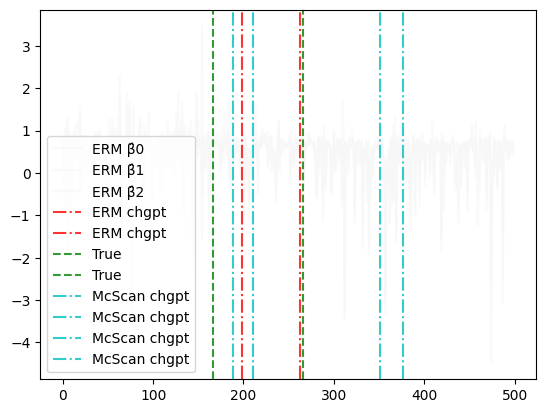

 13%|█▎        | 2/15 [00:34<03:45, 17.31s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [186 270]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  59 169 251

McScan_res:  [ 59 169 251]


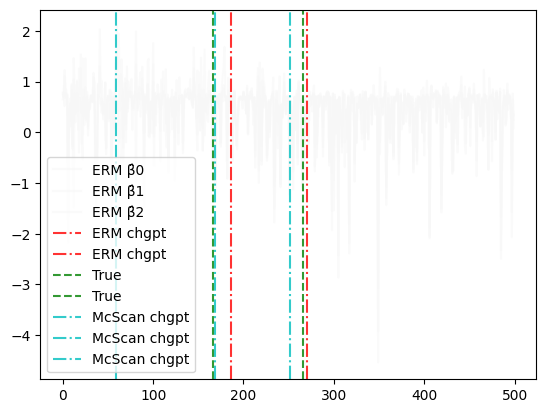

 20%|██        | 3/15 [00:48<03:13, 16.14s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [162 262]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 134 260

McScan_res:  [134 260]


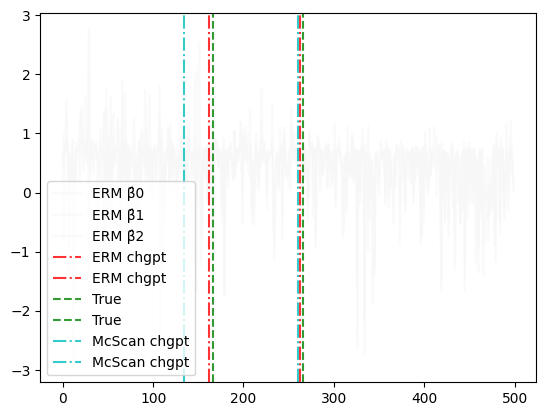

 27%|██▋       | 4/15 [00:58<02:29, 13.58s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [169 266]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 262 367

McScan_res:  [262 367]


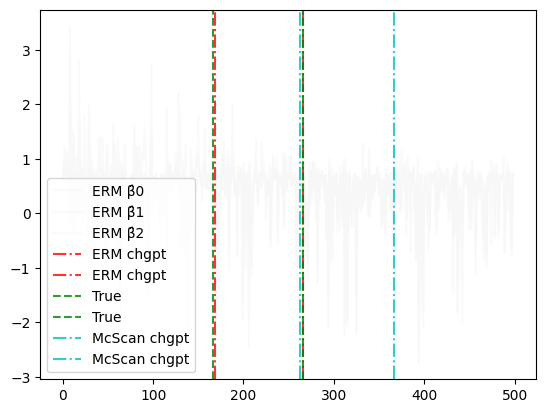

 33%|███▎      | 5/15 [01:09<02:04, 12.48s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [166 266]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 88

McScan_res:  [88]


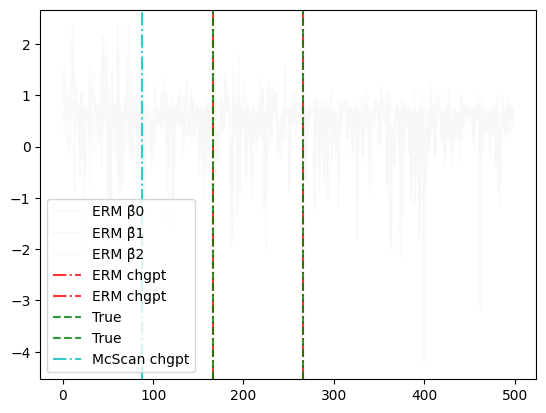

 40%|████      | 6/15 [01:14<01:31, 10.21s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [172 277]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 172 200 236

McScan_res:  [172 200 236]


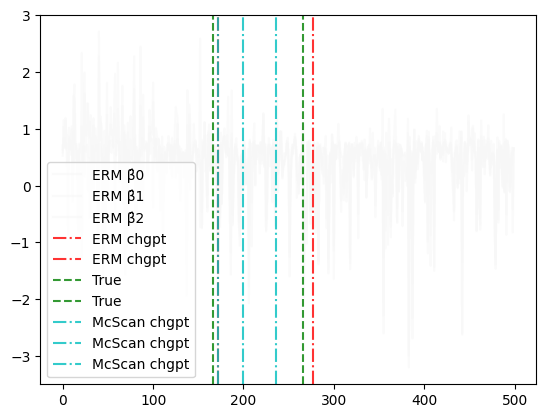

 47%|████▋     | 7/15 [01:29<01:32, 11.54s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [189 260]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 249

McScan_res:  [249]


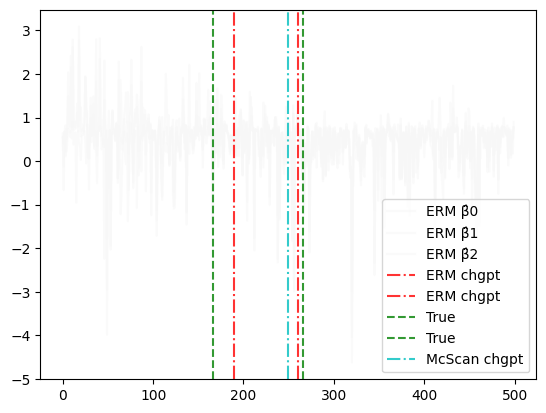

 53%|█████▎    | 8/15 [01:34<01:07,  9.62s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [171 271]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 174 225 295

McScan_res:  [174 225 295]


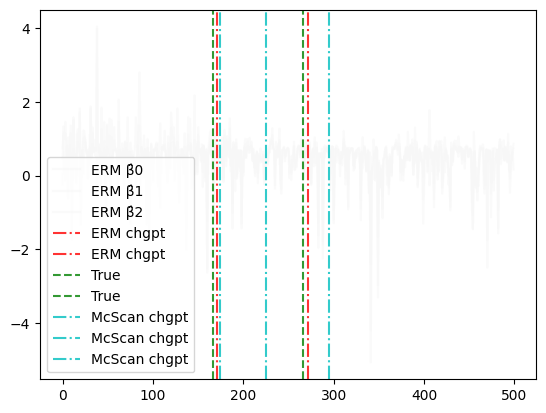

 60%|██████    | 9/15 [01:49<01:07, 11.28s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [175 271]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 122 148 289 314 402 454

McScan_res:  [122 148 289 314 402 454]


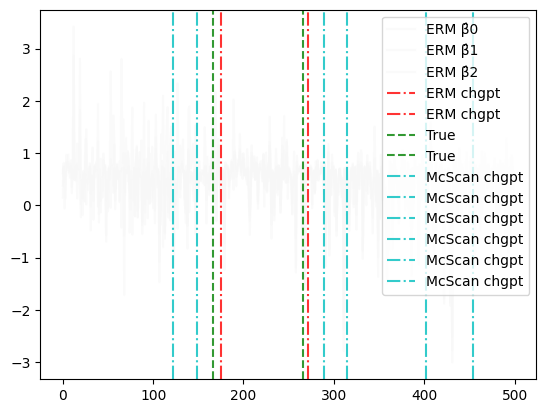

 67%|██████▋   | 10/15 [02:16<01:20, 16.16s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [187 264]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 126 152 349 446

McScan_res:  [126 152 349 446]


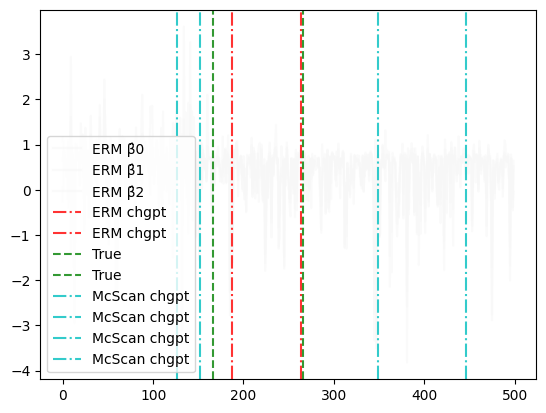

 73%|███████▎  | 11/15 [02:35<01:08, 17.04s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [175 264]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 262

McScan_res:  [262]


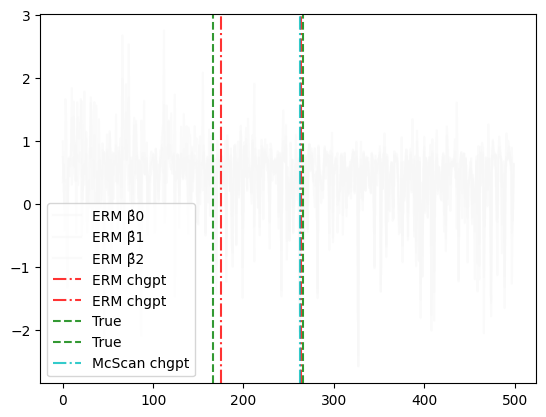

 80%|████████  | 12/15 [02:41<00:40, 13.59s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [210 265]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  94 276 300

McScan_res:  [ 94 276 300]


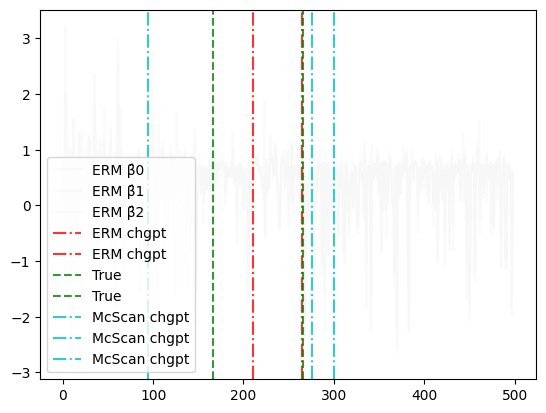

 87%|████████▋ | 13/15 [02:55<00:27, 13.65s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [187 264]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 281

McScan_res:  [281]


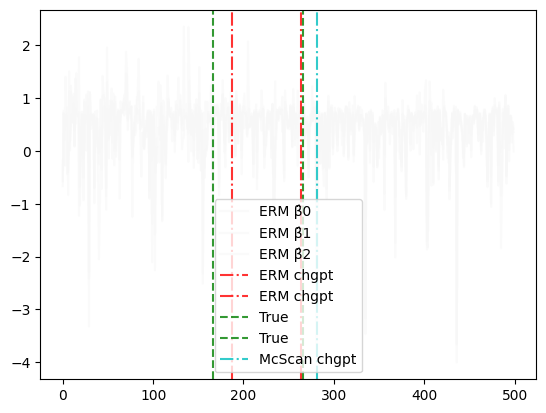

 93%|█████████▎| 14/15 [03:01<00:11, 11.28s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [166 267]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  89 150

McScan_res:  [ 89 150]


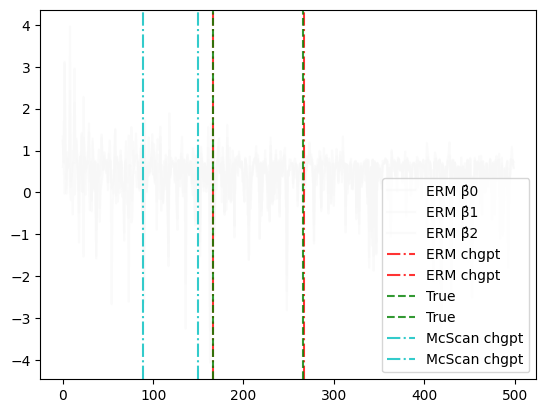

 71%|███████▏  | 5/7 [13:57<06:00, 180.12s/it]

δ =  3.0


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/478 [00:00<?, ?it/s]

  0%|          | 0/87153 [00:00<?, ?it/s]

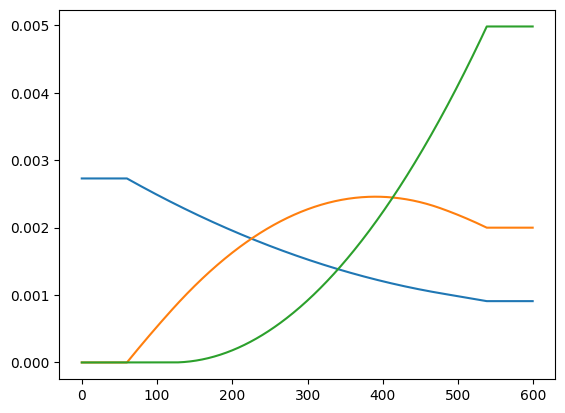

ρ:  [[0.62403206 0.00730266 0.03177474]
 [0.00730266 0.55407179 0.04824534]
 [0.03177474 0.04824534 0.51980839]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [199 319]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 133 157

McScan_res:  [133 157]


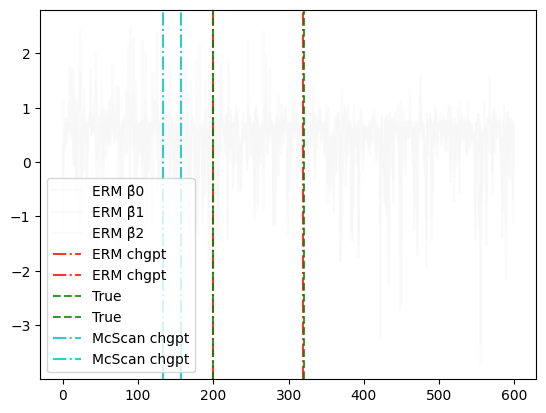

  7%|▋         | 1/15 [00:10<02:29, 10.65s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [227 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 149 395 431

McScan_res:  [149 395 431]


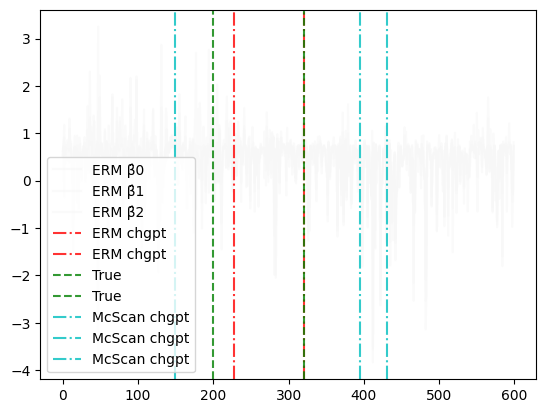

 13%|█▎        | 2/15 [00:25<02:50, 13.14s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [204 317]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 152 328

McScan_res:  [152 328]


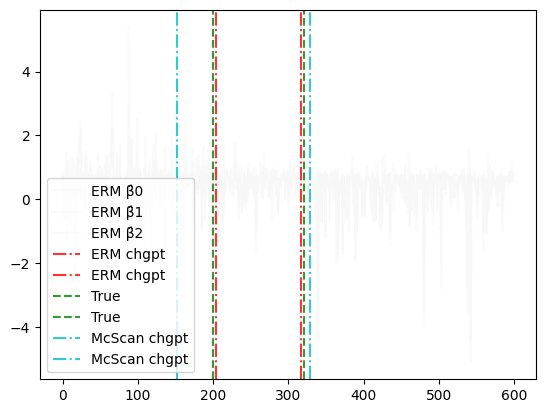

 20%|██        | 3/15 [00:36<02:24, 12.02s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [214 316]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 126 204 343

McScan_res:  [126 204 343]


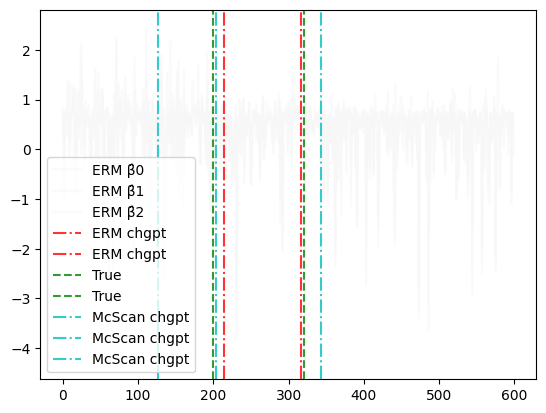

 27%|██▋       | 4/15 [00:50<02:23, 13.05s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [223 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  62 246 268 320 573

McScan_res:  [ 62 246 268 320 573]


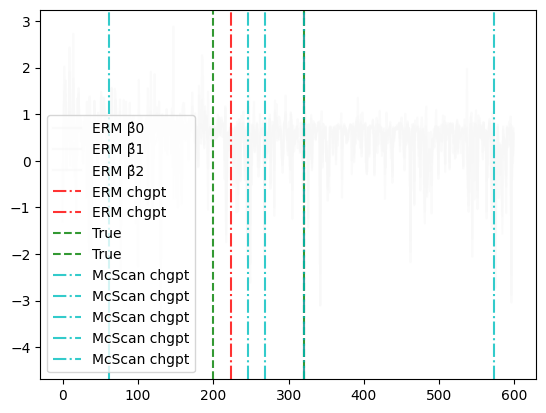

 33%|███▎      | 5/15 [01:14<02:49, 16.98s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [248 318]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 146 228 291

McScan_res:  [146 228 291]


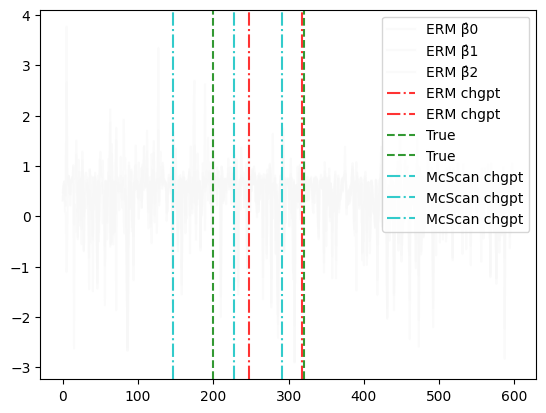

 40%|████      | 6/15 [01:29<02:25, 16.16s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [199 318]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 201 292 458

McScan_res:  [201 292 458]


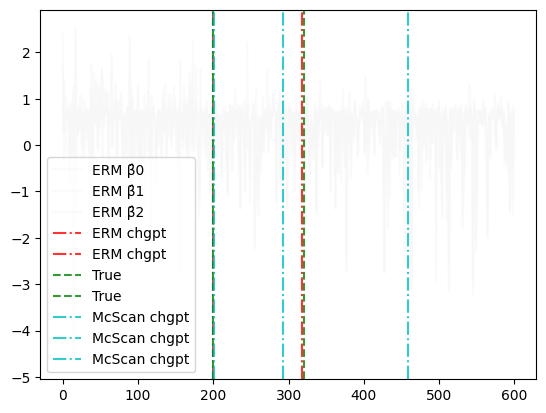

 47%|████▋     | 7/15 [01:43<02:05, 15.66s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [212 338]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 154 204 241

McScan_res:  [154 204 241]


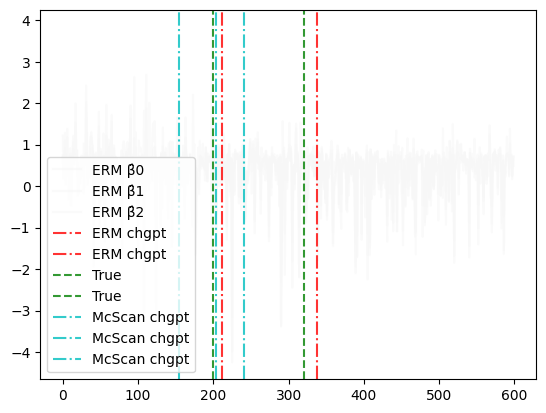

 53%|█████▎    | 8/15 [01:58<01:46, 15.18s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [225 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 185 357

McScan_res:  [185 357]


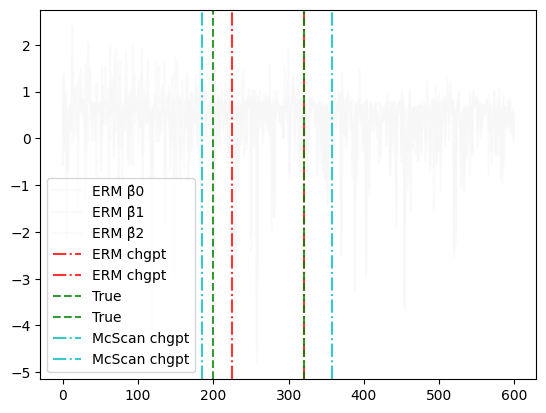

 60%|██████    | 9/15 [02:08<01:21, 13.63s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [228 329]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  27 112 340 539

McScan_res:  [ 27 112 340 539]


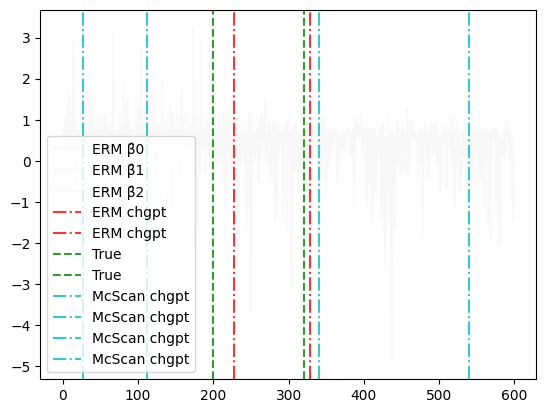

 67%|██████▋   | 10/15 [02:27<01:16, 15.29s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [209 325]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 170 228 253 351

McScan_res:  [170 228 253 351]


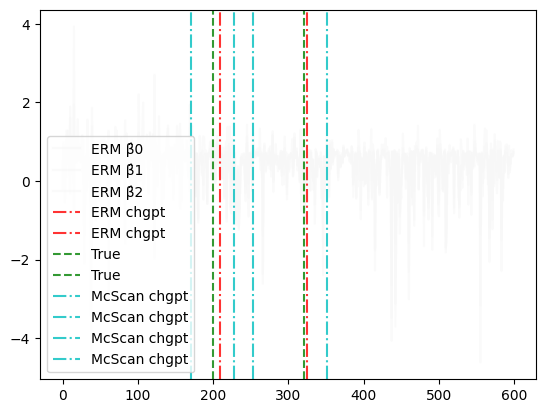

 73%|███████▎  | 11/15 [02:45<01:04, 16.20s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [206 319]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  37 341

McScan_res:  [ 37 341]


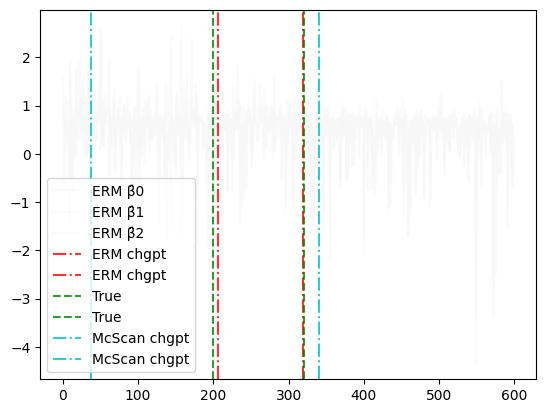

 80%|████████  | 12/15 [02:56<00:43, 14.43s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [199 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 227 355 446

McScan_res:  [227 355 446]


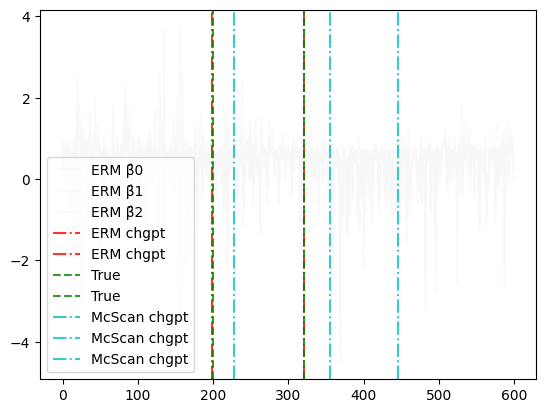

 87%|████████▋ | 13/15 [03:10<00:28, 14.41s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [210 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  99 159 335

McScan_res:  [ 99 159 335]


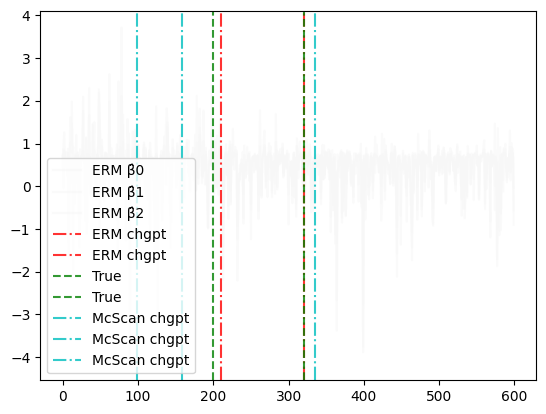

 93%|█████████▎| 14/15 [03:24<00:14, 14.42s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [216 320]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 203 242 450

McScan_res:  [203 242 450]


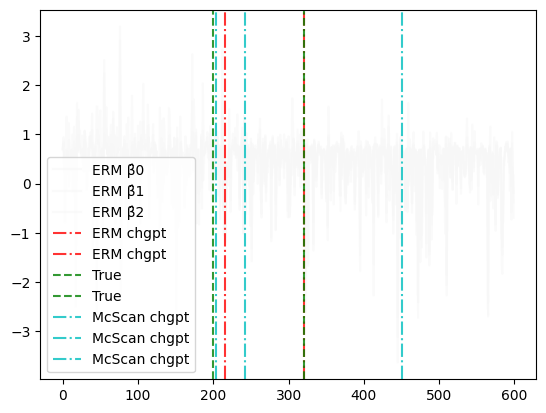

 86%|████████▌ | 6/7 [17:38<03:14, 194.00s/it]

δ =  3.5


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/558 [00:00<?, ?it/s]

  0%|          | 0/118828 [00:00<?, ?it/s]

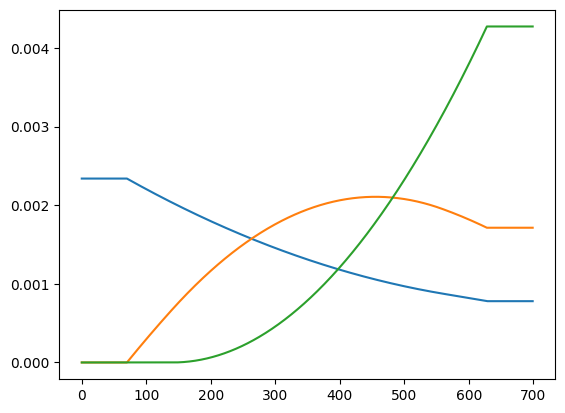

ρ:  [[0.49765273 0.01299617 0.01874746]
 [0.01299617 0.53122223 0.03854674]
 [0.01874746 0.03854674 0.41539231]]


  0%|          | 0/15 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [236 368]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 218 241

McScan_res:  [218 241]


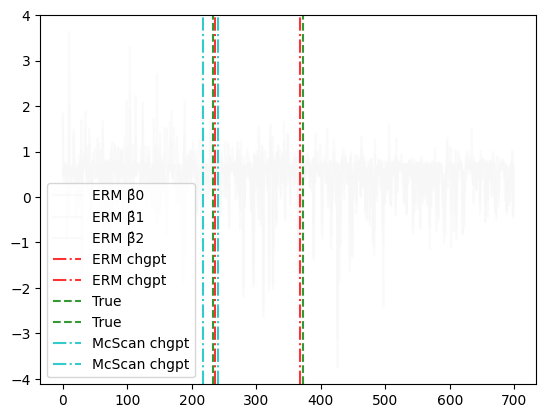

  7%|▋         | 1/15 [00:10<02:33, 10.94s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [234 376]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 252 402 486

McScan_res:  [252 402 486]


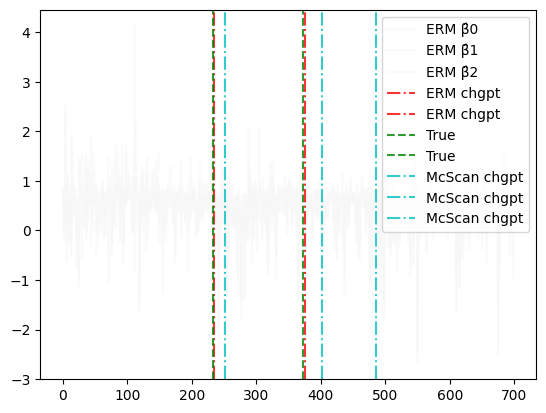

 13%|█▎        | 2/15 [00:26<02:54, 13.39s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [246 372]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  54  85 299

McScan_res:  [ 54  85 299]


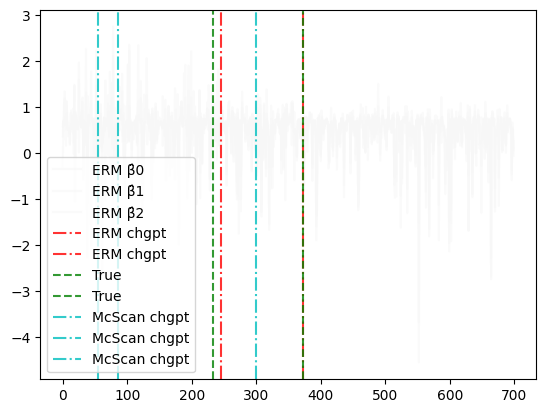

 20%|██        | 3/15 [00:40<02:46, 13.88s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [241 371]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!


R[write to console]: Error in La.svd(x, nu, nv) : erro de código 1 na rotina Lapack 'dgesdd'

R[write to console]: Além disso: 
R[write to console]: Warning messages:

R[write to console]: 1: Option grouped=FALSE enforced in cv.glmnet, since < 3 observations per fold 

R[write to console]: 2: Option grouped=FALSE enforced in cv.glmnet, since < 3 observations per fold 



McScan_res:  [-1]


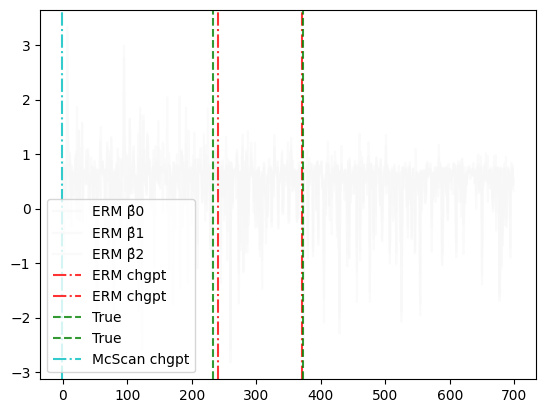

 27%|██▋       | 4/15 [00:46<01:57, 10.67s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [257 372]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 278 396 423 581

McScan_res:  [278 396 423 581]


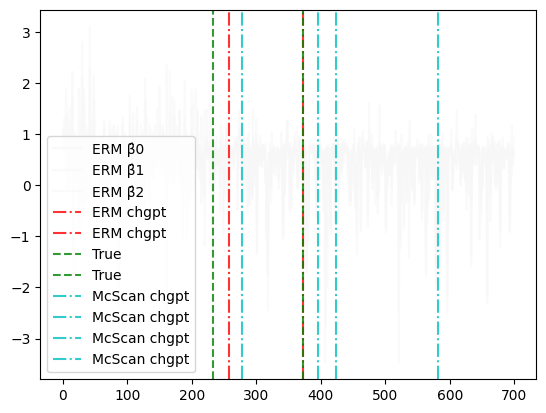

 33%|███▎      | 5/15 [01:05<02:17, 13.70s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [250 376]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  99 191 229 341 659

McScan_res:  [ 99 191 229 341 659]


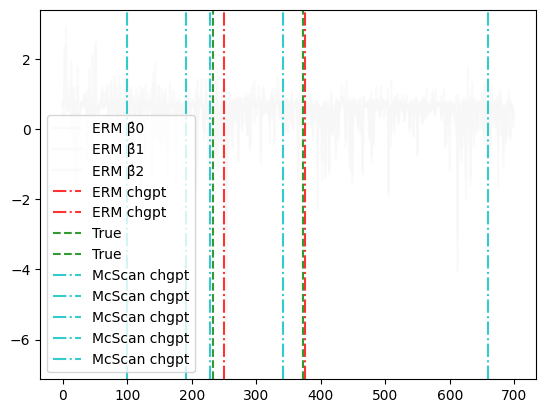

 40%|████      | 6/15 [01:28<02:31, 16.85s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [282 368]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 257 330

McScan_res:  [257 330]


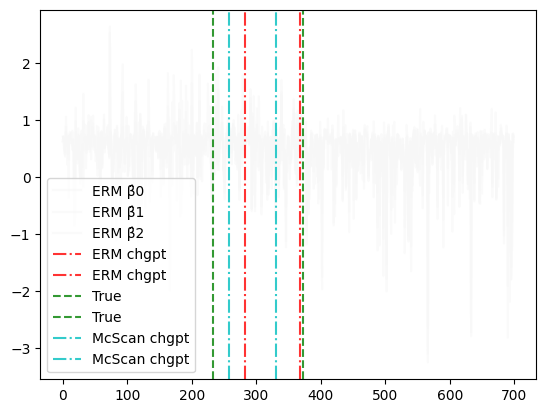

 47%|████▋     | 7/15 [01:38<01:57, 14.70s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [268 371]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 220 246 319

McScan_res:  [220 246 319]


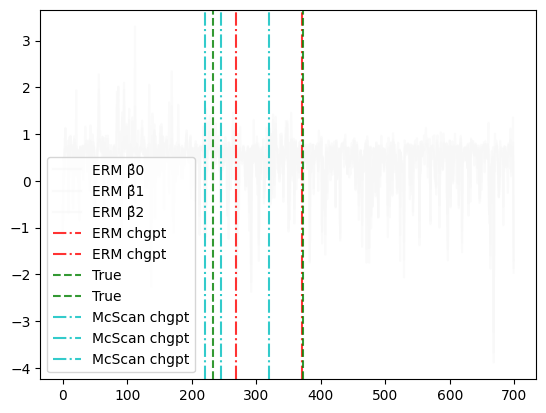

 53%|█████▎    | 8/15 [01:53<01:42, 14.71s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [239 372]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 103 293 360 667

McScan_res:  [103 293 360 667]


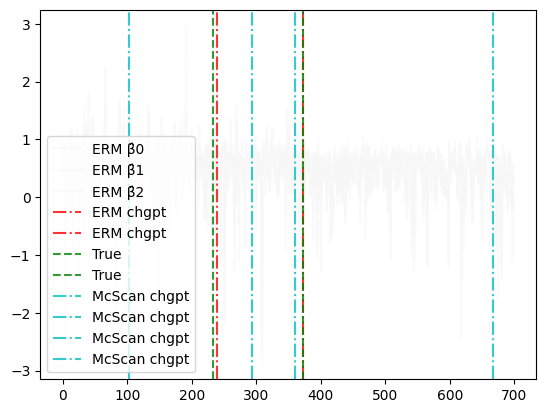

 60%|██████    | 9/15 [02:12<01:36, 16.00s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [289 373]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 203 215 341 436

McScan_res:  [203 215 341 436]


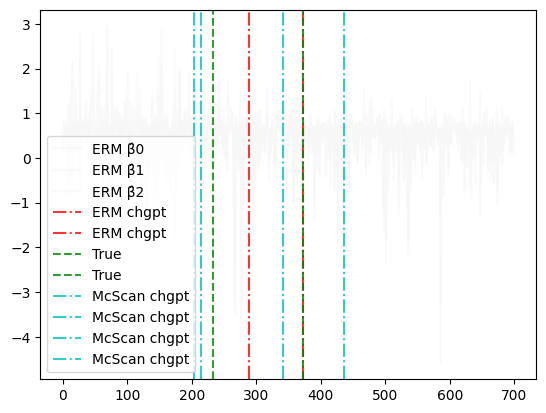

 67%|██████▋   | 10/15 [02:29<01:22, 16.55s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [271 375]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 110 172 354

McScan_res:  [110 172 354]


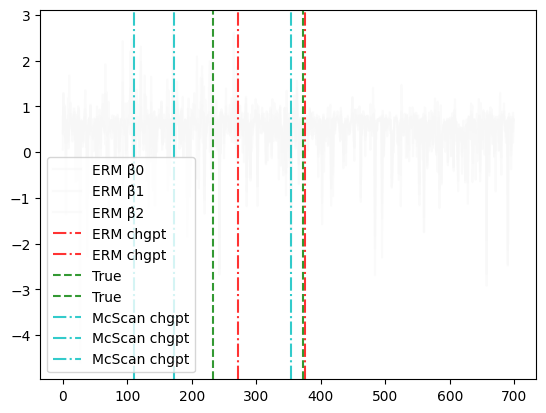

 73%|███████▎  | 11/15 [02:44<01:03, 15.97s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [234 373]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 131 230 242 383 513

McScan_res:  [131 230 242 383 513]


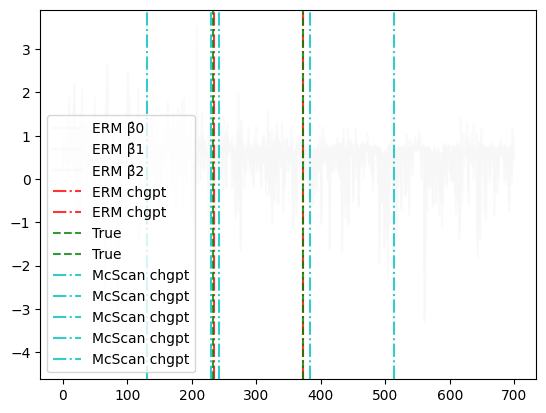

 80%|████████  | 12/15 [03:06<00:53, 17.87s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [303 374]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 186 282 397

McScan_res:  [186 282 397]


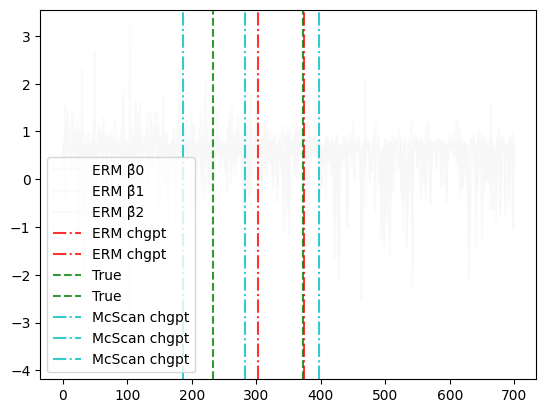

 87%|████████▋ | 13/15 [03:21<00:33, 16.78s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [264 373]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1] 234 330 460

McScan_res:  [234 330 460]


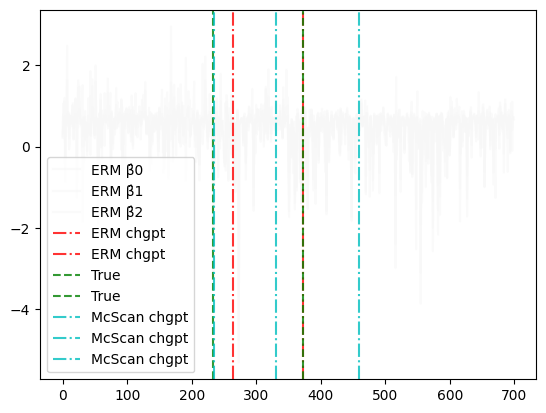

 93%|█████████▎| 14/15 [03:35<00:16, 16.07s/it]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...
WERM chpt estimate:  [232 367]
Done optimizing gof erm.
Running McScan...
Default threshold log(n*p)/2 is used!
Estimated changepoints from McScan:  [1]  45 235 484 552

McScan_res:  [ 45 235 484 552]


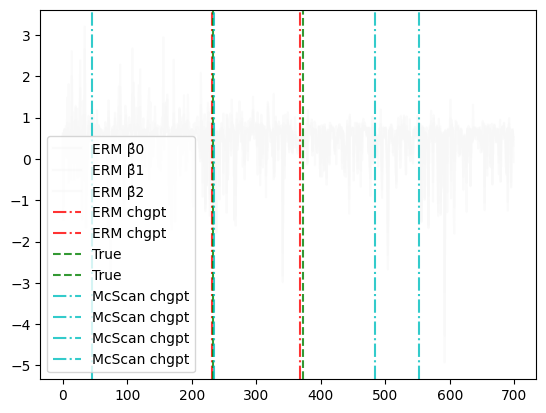

100%|██████████| 7/7 [21:34<00:00, 184.87s/it]
/Users/gabrielarpino/miniforge3/lib/python3.10/site-packages/numpy/lib/function_base.py:4573: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


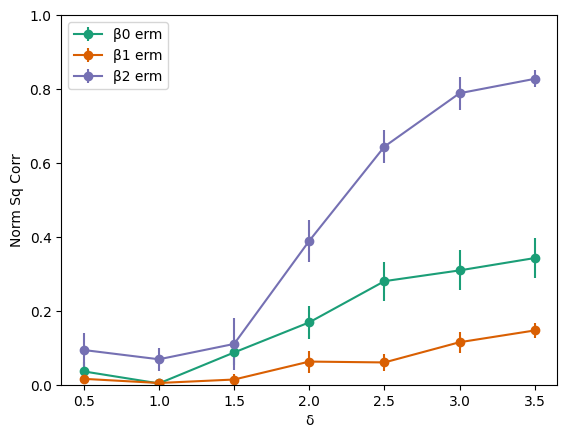

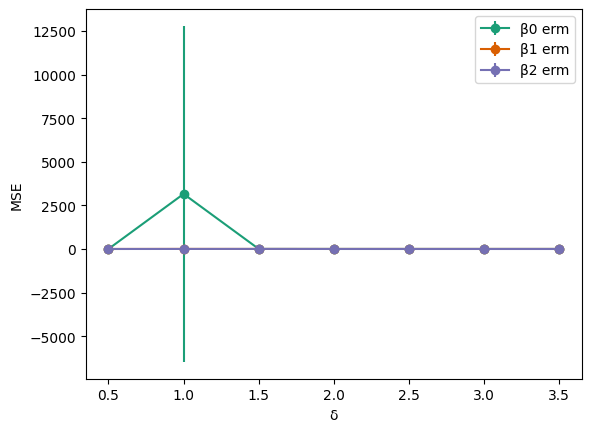

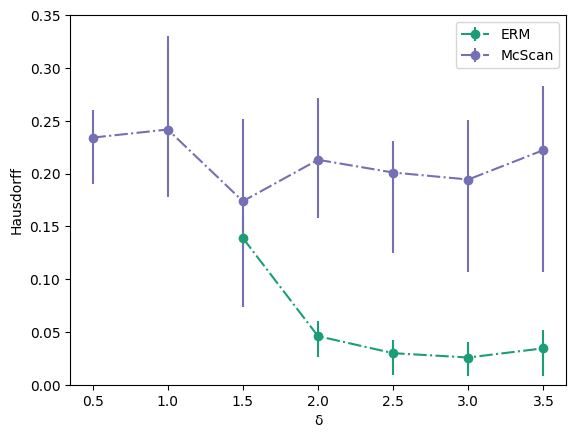

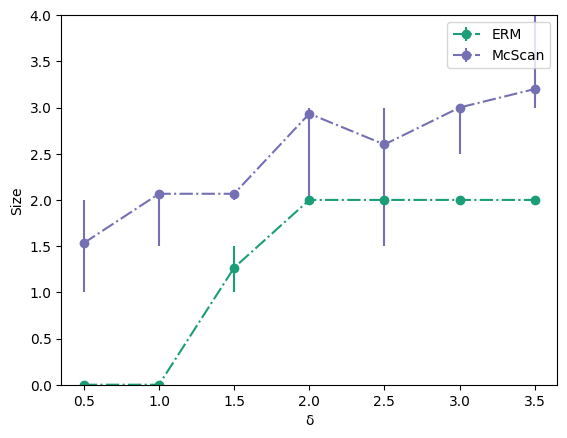

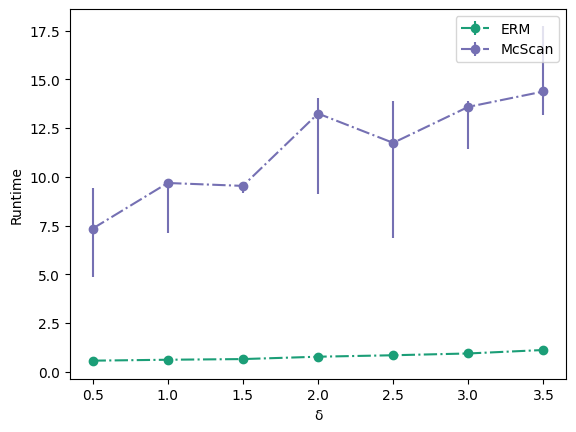

In [1]:
from WERM.config import unif_prior_to_η_ϕ, unif_prior_to_η_ϕ_combinations
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal, SparseGaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import WERM.gof
import WERM.performance_measures
import WERM.comparison
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(0)

p = 200
L = 3 # num signals. L-1 changepoints

δ_list = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]
noise_std = 0.1
num_trials = 15

fractional_chgpt_locations = np.array([1/3, 8/15])
# fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
ERM_size_arr = np.zeros((len(δ_list), num_trials))
ERM_runtime = np.zeros((len(δ_list), num_trials))
DCDP_haus_arr = np.zeros((len(δ_list), num_trials))
DCDP_size_arr = np.zeros((len(δ_list), num_trials))
DCDP_runtime = np.zeros((len(δ_list), num_trials))
McScan_haus_arr = np.zeros((len(δ_list), num_trials))
McScan_size_arr = np.zeros((len(δ_list), num_trials))
McScan_runtime = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    # Changepoint locations
    Δ = lambda n: int(n/10)

    # For estimating size
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    # For estimating location
    # Lmin = L
    # Lmax = L
    # p_l = None
    # num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    ϕ_normalized = ϕ / ϕ.sum(axis = 1)[:, None]
    plt.plot(ϕ_normalized.T)
    plt.show()
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    # Subsampling
    # subsample_factor = 1
    # n_subsampled = int(n/subsample_factor)
    # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # η_arr_subsampled = η_arr_subsampled * subsample_factor # Rescale η_arr_subsampled to match η_arr

    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            Σ[i_, j_] = 0.00 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    # γ_squared_over_δ = 8
    # # Design a non-trivial LxL covariance
    # covvy = np.zeros((L, L))
    # for i_ in range(L):
    #     for j_ in range(L):
    #         covvy[i_, j_] = 0.25 ** (np.abs(i_ - j_))
    # # covvy = np.block([[1, 0.4], [0.4, 1]])
    # B̃_cov = γ_squared_over_δ * δ * covvy # keeps the signal power fixed
    # signal_prior = GaussianSignal(B̃_cov)

    # Sparse Gaussian Signal Prior
    α = 0.5 # fraction of nonzeros
    σ_l_arr = np.array([np.sqrt(δ) for ℓ in range(L)]) # signal standard deviation
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # Sparse Difference Signal Prior
    # α = 0.25 # fraction of nonzeros
    # # σ_l_arr = np.array([2.5, 2.5]) # signal standard deviation
    # var_β_1 = 1
    # σ_w = 1
    # signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T

        Θ = X @ B̃
        y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

        # --- Run Weighted ERM --- #
        B̂_erm = np.zeros((p, L))
        β̂_erm_list = [None for ℓ_ in range(L)]

        # Time the execution of the ERM and save it
        start_time_ERM = time.time()
        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]

            print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            print("Done regressing on signal.")
            β̂_erm = sk_lin_reg.coef_
            β̂_erm_list[ℓ_] = β̂_erm

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.lin_reg_opt_chgpt_gof(X @ B̂_erm, y, η_arr, p_η_arr, σ = noise_std, ϵ = 0.005)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        ERM_runtime[i, trial_num] = time.time() - start_time_ERM

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        ERM_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        ### --- Run DCDP, and record the runtime --- ###
        # start_time_DCDP = time.time()
        # print("Running DCDP...")
        # DCDP_res = np.array(WERM.comparison.DCDP(X, np.array(y), λ_list = [0.1, 1, 5, 10], γ_list = [100, 500, 1000]))
        # print("DCDP_res: ", DCDP_res)
        # DCDP_runtime[i, trial_num] = time.time() - start_time_DCDP
        # # plot a vertical line at the DCDP estimated change point location
        # [plt.axvline(x=loc, color = 'b', linestyle='-.', alpha = 0.8, label="DCDP chgpt") for loc in DCDP_res]
        # DCDP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(DCDP_res, true_chgpt_locations(n)))
        # DCDP_size_arr[i, trial_num] = (len(DCDP_res[DCDP_res != -1]))

        ### --- Run McScan and record the runtime --- ###
        start_time_McScan = time.time()
        print("Running McScan...")
        try: 
            McScan_res = np.array(WERM.comparison.run_mcscan(X, np.array(y).reshape(-1, 1)))
        except:
            McScan_res = np.array([-1])
        print("McScan_res: ", McScan_res)
        McScan_runtime[i, trial_num] = time.time() - start_time_McScan
        # plot a vertical line at the McScan estimated change point location
        [plt.axvline(x=loc, color='c', linestyle='-.', alpha = 0.8, label="McScan chgpt") for loc in McScan_res]
        McScan_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(McScan_res, true_chgpt_locations(n)))
        McScan_size_arr[i, trial_num] = (len(McScan_res[McScan_res != -1]))

        plt.legend()
        plt.show()

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_haus_arr, axis = 1) - np.percentile(DCDP_haus_arr, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_haus_arr, 75, axis = 1) - np.mean(DCDP_haus_arr, axis = 1)
# DCDP_haus_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_haus_asymmetric_err[0][DCDP_haus_asymmetric_err[0] < 0] = 0
# DCDP_haus_asymmetric_err[1][DCDP_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_size_arr, axis = 1) - np.percentile(DCDP_size_arr, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_size_arr, 75, axis = 1) - np.mean(DCDP_size_arr, axis = 1)
# DCDP_size_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_size_asymmetric_err[0][DCDP_size_asymmetric_err[0] < 0] = 0
# DCDP_size_asymmetric_err[1][DCDP_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0
# DCDP_lower_err = np.mean(DCDP_runtime, axis = 1) - np.percentile(DCDP_runtime, 25, axis = 1)
# DCDP_upper_err = np.percentile(DCDP_runtime, 75, axis = 1) - np.mean(DCDP_runtime, axis = 1)
# DCDP_runtime_asymmetric_err = [DCDP_lower_err, DCDP_upper_err]
# DCDP_runtime_asymmetric_err[0][DCDP_runtime_asymmetric_err[0] < 0] = 0
# DCDP_runtime_asymmetric_err[1][DCDP_runtime_asymmetric_err[1] < 0] = 0

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_haus_arr, axis = 1), yerr = DCDP_haus_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_size_arr, axis = 1), yerr = DCDP_size_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(DCDP_runtime, axis = 1), yerr = DCDP_runtime_asymmetric_err, label="DCDP", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-.", c=PAL[2], alpha = 1.0)
plt.xlabel("δ")
plt.ylabel("Runtime")
plt.legend()
plt.show()

### Plot against DCDP results from [Arpino et al. 2024]

/Users/gabrielarpino/miniforge3/lib/python3.10/site-packages/numpy/lib/function_base.py:4573: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


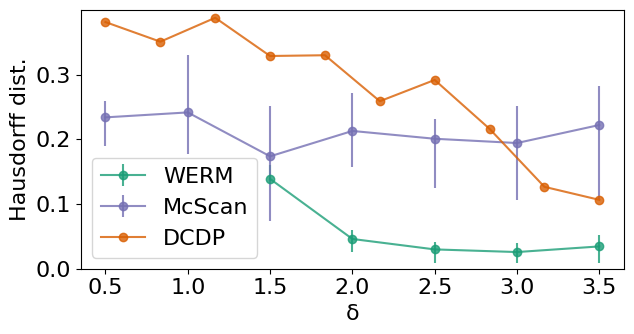

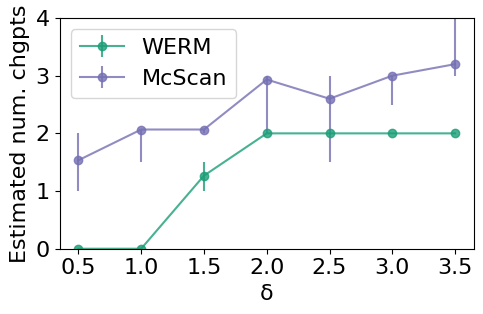

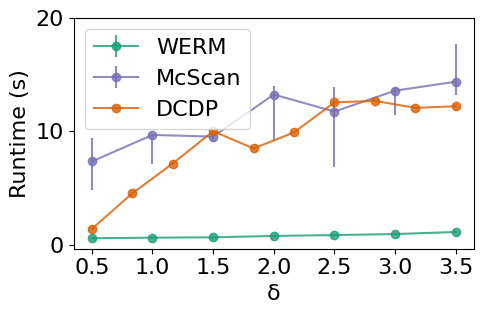

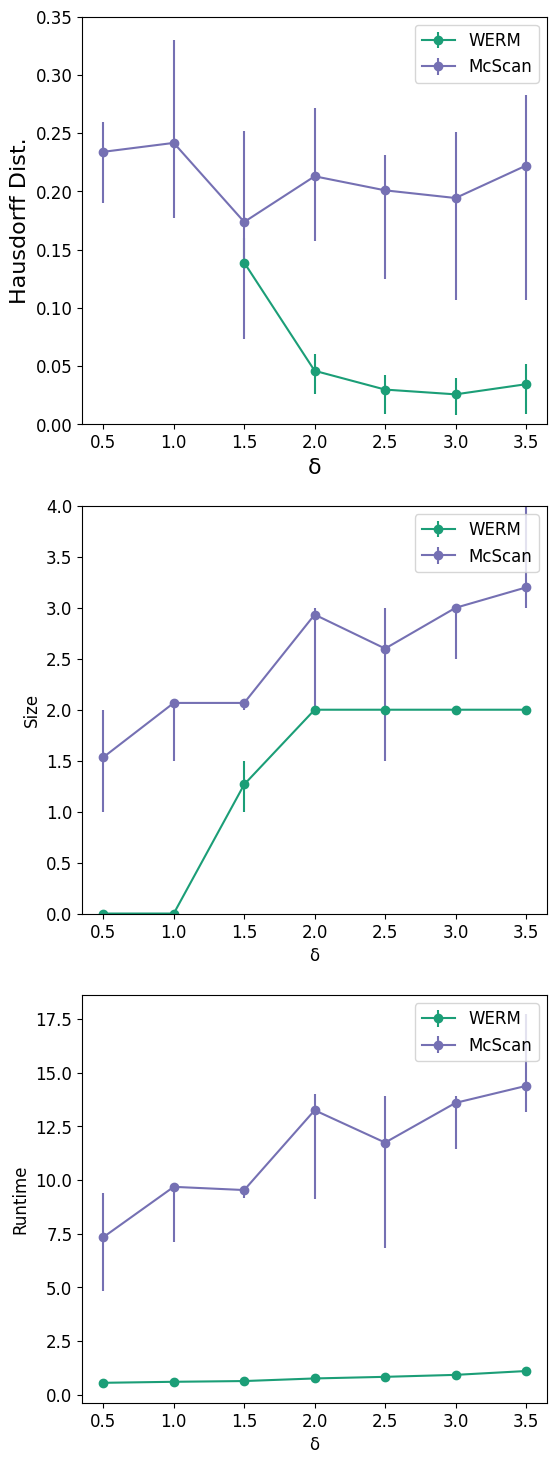

In [25]:
# Save the results
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_corr_arr.npy", erm_corr_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/erm_MSE_arr.npy", erm_MSE_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_haus_arr.npy", ERM_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_size_arr.npy", ERM_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/ERM_runtime.npy", ERM_runtime)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_haus_arr.npy", DCDP_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/DCDP_size_arr.npy", DCDP_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_haus_arr.npy", McScan_haus_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_size_arr.npy", McScan_size_arr)
np.save("results/linear_model_comparison/McScan_sparse_signal_comparison/McScan_runtime.npy", McScan_runtime)

### --- Load DCDP results from Arpino et al. 2024 --- ###
δ_list_DCDP = np.array([0.5, 0.83333, 1.166666666667, 1.5, 1.833333333333, 2.166666666667, 2.5, 2.833333333333, 3.166666666667, 3.5])
DCDP_haus_avg = np.array([0.38133333333333, 0.351004016064257, 0.387982832618026, 0.328888888888889, 0.330054644808743, 0.25896843725943, 0.291866666666667, 0.216254416961131, 0.126592943654555, 0.10647619047619])
DCDP_runtime_avg = np.array([1.38509448634254, 4.52350546254052, 7.15471697648366, 10.0103385514683, 8.4857648147477, 9.90291733079487, 12.5548102445073, 12.6848777294159, 12.0718481077088, 12.2109361767769])

### --- Prepare asymmetric error bars for matplotlib, and ensure that the error bars are not negative --- ###
ERM_lower_err = np.mean(ERM_haus_arr, axis = 1) - np.percentile(ERM_haus_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_haus_arr, 75, axis = 1) - np.mean(ERM_haus_arr, axis = 1)
ERM_haus_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_haus_asymmetric_err[0][ERM_haus_asymmetric_err[0] < 0] = 0
ERM_haus_asymmetric_err[1][ERM_haus_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_haus_arr, axis = 1) - np.percentile(McScan_haus_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_haus_arr, 75, axis = 1) - np.mean(McScan_haus_arr, axis = 1)
McScan_haus_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_haus_asymmetric_err[0][McScan_haus_asymmetric_err[0] < 0] = 0
McScan_haus_asymmetric_err[1][McScan_haus_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_size_arr, axis = 1) - np.percentile(ERM_size_arr, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_size_arr, 75, axis = 1) - np.mean(ERM_size_arr, axis = 1)
ERM_size_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_size_asymmetric_err[0][ERM_size_asymmetric_err[0] < 0] = 0
ERM_size_asymmetric_err[1][ERM_size_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_size_arr, axis = 1) - np.percentile(McScan_size_arr, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_size_arr, 75, axis = 1) - np.mean(McScan_size_arr, axis = 1)
McScan_size_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_size_asymmetric_err[0][McScan_size_asymmetric_err[0] < 0] = 0
McScan_size_asymmetric_err[1][McScan_size_asymmetric_err[1] < 0] = 0

ERM_lower_err = np.mean(ERM_runtime, axis = 1) - np.percentile(ERM_runtime, 25, axis = 1)
ERM_upper_err = np.percentile(ERM_runtime, 75, axis = 1) - np.mean(ERM_runtime, axis = 1)
ERM_runtime_asymmetric_err = [ERM_lower_err, ERM_upper_err]
ERM_runtime_asymmetric_err[0][ERM_runtime_asymmetric_err[0] < 0] = 0
ERM_runtime_asymmetric_err[1][ERM_runtime_asymmetric_err[1] < 0] = 0
McScan_lower_err = np.mean(McScan_runtime, axis = 1) - np.percentile(McScan_runtime, 25, axis = 1)
McScan_upper_err = np.percentile(McScan_runtime, 75, axis = 1) - np.mean(McScan_runtime, axis = 1)
McScan_runtime_asymmetric_err = [McScan_lower_err, McScan_upper_err]
McScan_runtime_asymmetric_err[0][McScan_runtime_asymmetric_err[0] < 0] = 0
McScan_runtime_asymmetric_err[1][McScan_runtime_asymmetric_err[1] < 0] = 0

### --- Replot the figures individually --- ###
δ_arr = np.array([δ_list for _ in range(num_trials)])
# Hausdorff plots
fig = plt.figure(figsize = (6.5, 3.5))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_haus_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.ylim((0, 0.4))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Hausdorff dist.", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks([0, 0.1, 0.2, 0.3], fontsize=16)
plt.legend(prop={'size': 16}, loc='lower left')
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_haus" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Size plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.ylim((0, L + 1))
plt.xlabel("δ", fontsize=16)
plt.ylabel("Estimated num. chgpts", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_size" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
fig = plt.figure(figsize = (5, 3.3))
cmap = plt.get_cmap('RdBu')
plt.rcParams.update({'font.size': 12})
plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 0.8)
plt.errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 0.8)
plt.errorbar(δ_list_DCDP, DCDP_runtime_avg, yerr = None, label="DCDP", marker="o", ls="-", c=PAL[1], alpha = 0.8)
plt.xlabel("δ", fontsize=16)
plt.ylabel("Runtime (s)", fontsize=16)
plt.legend(prop={'size': 16})
plt.xticks(fontsize=16)
plt.yticks([0, 10, 20], fontsize=16)
fig.tight_layout()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison_runtime" + str(L) + "_Lstar" + str(fractional_chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Plot the above three figures on top of each other as subplots
fig, axs = plt.subplots(3, 1, figsize=(6, 18))

# Hausdorff estimation plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
axs[0].errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = ERM_haus_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[0].errorbar(δ_list, np.mean(McScan_haus_arr, axis = 1), yerr = McScan_haus_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[0].set_ylim((0, 0.35))
axs[0].set_xlabel("δ", fontsize=16)
axs[0].set_ylabel("Hausdorff Dist.", fontsize=16)
axs[0].legend()

# Hausdorff size plots
axs[1].errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = ERM_size_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[1].errorbar(δ_list, np.mean(McScan_size_arr, axis = 1), yerr = McScan_size_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[1].set_ylim((0, L + 1))
axs[1].set_xlabel("δ")
axs[1].set_ylabel("Size")
axs[1].legend()

# Runtime plots
axs[2].errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = ERM_runtime_asymmetric_err, label="WERM", marker="o", ls="-", c=PAL[0], alpha = 1.0)
axs[2].errorbar(δ_list, np.mean(McScan_runtime, axis = 1), yerr = McScan_runtime_asymmetric_err, label="McScan", marker="o", ls="-", c=PAL[2], alpha = 1.0)
axs[2].set_xlabel("δ")
axs[2].set_ylabel("Runtime")
axs[2].legend()
plt.savefig("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison.pdf")

# Save the figure as a tikz file, and use a workaround to make the legend work
import tikzplotlib
def tikzplotlib_fix_ncols(obj):
    """
    workaround for matplotlib 3.6 renamed legend's _ncol to _ncols, which breaks tikzplotlib
    """
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    for child in obj.get_children():
        tikzplotlib_fix_ncols(child)
tikzplotlib_fix_ncols(fig)
tikzplotlib.save("figures/linear_model_comparison/McScan_sparse_signal_comparison/linear_model_comparison.tex")


plt.show()



### Include DCDP and other results from (Arpino et al 2024) onto the same plot